# 66. Direct direction and magnitude supervision for large-angle calibration

This experiment trains on **one calibration prior per physical window**, sampled from the same mixed Student-t fine / uniform coarse distributions as before. There is **no +/− pair objective, no geodesic path construction, no intermediate path supervision and no consistency loss**.

Training rotation terms are separately weighted SO(3) geodesic, correction-axis direction, and correction-magnitude losses. The stochastic probe restores the original model after training; full training and scratch / weights / resume checkpoint modes are unchanged. Exact-angle and chronological rollout diagnostics remain available.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters


In [57]:
RUN_NAME = 'kaist_large_paired_003.3_3d_direction_magnitude'

RANDOM_SEED = 12345
TRAIN_PAIR_SEED, VALIDATION_PAIR_SEED, TEST_PAIR_SEED = 23456, 34567, 45678
VISUALIZATION_PAIR_SEED = 56789
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
CALIBRATION_CONTEXT_DIM = 7
KAIST_TAU_IMU_S, KAIST_TAU_LIDAR_S, KAIST_TAU_LIDAR_RIGHT_S = 0.0, -0.025, -0.035
REFINED_TAU_BY_SENSOR_S = {'imu': KAIST_TAU_IMU_S, 'lidar': KAIST_TAU_LIDAR_S, 'lidar_right': KAIST_TAU_LIDAR_RIGHT_S}

WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE, NUM_WORKERS, DROP_LAST_TRAIN = 16, 0, True
NUM_EPOCHS, LEARNING_RATE, WEIGHT_DECAY, GRADIENT_CLIP_NORM = 200, 7.5e-5, 1e-4, 1.0
CHECKPOINT_EVERY_EPOCHS, PRINT_EVERY_BATCHES = 3, 500
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0

# Original Notebook 58-style rotation/translation/time distributions.
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 60.0, 179.0
COARSE_PRIOR_PROBABILITY = 0.50                 # Set 0.80 and min=120 to reproduce Notebook 58's angle mix.
STUDENT_T_DOF = 3.0
PRIOR_TRANSLATION_MAX_M, PRIOR_TRANSLATION_SCALE_M = 0.05, 0.02
# PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.50, 0.25
PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.001, 0.0005
# TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.001

# Direct GT supervision. All three rotation terms are separately logged and weighted.
CORRECTION_LOSS_TYPE = 'mse'
ROTATION_SUPERVISION_MODE = 'so3'               # Used only by historical +/-pair evaluation helpers.
ROTATION_LOSS_SCALE_RAD = np.deg2rad(60.0)
ROTATION_GEODESIC_WEIGHT = 1.0                 # Set to 0 for pure direction+magnitude ablation.
ROTATION_DIRECTION_WEIGHT = 5.0                # Angular-axis alignment, 1 - cosine.
ROTATION_MAGNITUDE_WEIGHT = 1.0                # Squared normalized magnitude error.
ROTATION_DIRECTION_MIN_TARGET_DEG = 1.0        # Axis is meaningless near an exact zero correction.
ROTATION_DIRECTION_EPS_RAD = 1e-3              # Stable normalization near a zero predicted vector.
ACTIVE_ROTATION_WEIGHT = 1.0                  # Rotation regression for faulted examples.
HEALTHY_ROTATION_WEIGHT = 0.1                 # Preserve low drift from unperturbed sensors.
TRANSLATION_LOSS_SCALE_M, TIME_OFFSET_LOSS_SCALE_S = 0.05, 0.05
ROTATION_LOSS_WEIGHT, TRANSLATION_LOSS_WEIGHT, TIME_OFFSET_LOSS_WEIGHT = 2.0, 0.0, 0.0

# One independently sampled faulty calibration per physical window. No path points.
LEGACY_PAIR_EVAL_WEIGHT = 0.0                 # Evaluation-only +/-pair helper; never in training.
TRUTH_ANCHOR_LOSS_WEIGHT = 0.0               # Legacy +/-pair diagnostics only.
CHANGE_EVENT_LOSS_WEIGHT, CHANGE_TIME_LOSS_WEIGHT = 0.0, 0.0

# Stochastic and full runs both use the same weights loaded during model construction.
RUN_STOCHASTIC_PAIR_TEST = True
RUN_FULL_TRAINING = True                   # Enable only after inspecting the reversible stochastic diagnostic.
REQUIRE_STOCHASTIC_GATE = False

# Select exactly one initialization mode:
#   'scratch': new random model, epoch 0, new AdamW/scheduler.
#   'weights': load MODEL weights only from another run, epoch 0, new AdamW/scheduler.
#   'resume': restore model + AdamW + scheduler + epoch + RNG from this run's last.pt.
INITIALIZATION_MODE = 'weights'   # 'scratch', 'weights', or 'resume'
# INITIAL_WEIGHTS_CHECKPOINT = ROOT / 'runs' / 'kaist_large_paired_003.3_3d_large' / 'best.pt'
INITIAL_WEIGHTS_CHECKPOINT = ROOT / 'runs' / 'kaist_large_paired_003.2_3d' / 'best.pt'
RESUME_CHECKPOINT = ROOT / 'runs' / RUN_NAME / 'last.pt'
# In 'weights' mode, use a NEW RUN_NAME so the source checkpoint cannot be overwritten.

assert 0 < FINE_ROTATION_MAX_DEG <= COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180
assert 0 <= COARSE_PRIOR_PROBABILITY <= 1
assert len(CALIBRATION_KEYS) == 3
assert ROTATION_GEODESIC_WEIGHT >= 0 and ROTATION_DIRECTION_WEIGHT >= 0 and ROTATION_MAGNITUDE_WEIGHT >= 0
assert ROTATION_GEODESIC_WEIGHT + ROTATION_DIRECTION_WEIGHT + ROTATION_MAGNITUDE_WEIGHT > 0
assert HEALTHY_ROTATION_WEIGHT > 0 and ACTIVE_ROTATION_WEIGHT > 0
print('Rotation component weights: geo=', ROTATION_GEODESIC_WEIGHT, 'dir=', ROTATION_DIRECTION_WEIGHT, 'mag=', ROTATION_MAGNITUDE_WEIGHT)

if INITIALIZATION_MODE not in ('scratch', 'weights', 'resume'):
    raise ValueError(f'Unknown INITIALIZATION_MODE={INITIALIZATION_MODE!r}')

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
print('Device:', DEVICE, '| keys:', CALIBRATION_KEYS)
print('Fine Student-t:', (0, FINE_ROTATION_MAX_DEG), 'scale', FINE_ROTATION_SCALE_DEG, 'coarse uniform:', (COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), 'p:', COARSE_PRIOR_PROBABILITY)
print('Reference KAIST tau [ms]:', {k: 1000 * v for k, v in REFINED_TAU_BY_SENSOR_S.items()})
print('Initialization:', INITIALIZATION_MODE, '| checkpoint:', {'scratch': None, 'weights': INITIAL_WEIGHTS_CHECKPOINT, 'resume': RESUME_CHECKPOINT}[INITIALIZATION_MODE])


Rotation component weights: geo= 1.0 dir= 5.0 mag= 1.0
Device: cuda | keys: ('imu', 'lidar', 'lidar_right')
Fine Student-t: (0, 60.0) scale 30.0 coarse uniform: (60.0, 179.0) p: 0.5
Reference KAIST tau [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}
Initialization: weights | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.2_3d/best.pt


## 3. KAIST split, calibration, datasets, and loaders


In [40]:
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')

TRAIN_NAMES = ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
VAL_NAMES = ['Urban26', 'Urban28']
TEST_NAMES = ['Urban38', 'Urban39']
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError('Train, validation and test sequences overlap.')

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152, 0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)
T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
print('Sequences:', TRAIN_NAMES, VAL_NAMES, TEST_NAMES)
print('Reference offsets [ms]:', {key: 1000 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


Sequences: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16'] ['Urban26', 'Urban28'] ['Urban38', 'Urban39']
Reference offsets [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Required right LiDAR odometry missing for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset_65(names, rig):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_dataset_65(TRAIN_NAMES, rig_calibration)
val_dataset = make_dataset_65(VAL_NAMES, rig_calibration)
test_dataset = make_dataset_65(TEST_NAMES, rig_calibration)

for split_name, dataset in (('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f'{split_name} keys: {tuple(dataset.calibration_keys)} != {CALIBRATION_KEYS}')
    sample = collate_windows([dataset[0]])
    for key, expected in REFINED_TAU_BY_SENSOR_S.items():
        actual = float(sample.current_calibration[key].time_offset.reshape(-1)[0].item())
        assert abs(actual - expected) < 2e-6, f'{split_name}/{key}: expected {expected}, got {actual}'
    print(dataset.summary())

# Like Notebook 58: reference tau must not silently shift raw measurements or timestamps.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right, tau_imu_s=0.0, tau_lidar_s=0.0, tau_lidar_right_s=0.0)
zero_clock_control = make_dataset_65([VAL_NAMES[0]], zero_clock_rig)
corrected_clock_control = make_dataset_65([VAL_NAMES[0]], rig_calibration)
if len(zero_clock_control) != len(corrected_clock_control):
    raise AssertionError('Changing reference tau changed the number of windows.')
for index in sorted({0, len(zero_clock_control) // 2, len(zero_clock_control) - 1}):
    original, corrected = zero_clock_control[index], corrected_clock_control[index]
    for stream_name, original_stream in original.streams.items():
        new_stream = corrected.streams[stream_name]
        torch.testing.assert_close(original_stream.values, new_stream.values)
        torch.testing.assert_close(original_stream.timestamps, new_stream.timestamps)
        if original_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(original_stream.interval_start_timestamps, new_stream.interval_start_timestamps)
print('KAIST temporal reference check: corrected τ targets, raw measurements and timestamps unchanged.')


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR

In [41]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Shared physical augmentation and mixed 3D prior sampler

Each sampled batch contains **fine truncated Student-t** or **coarse uniform** rotation magnitudes independently per example. Positive and negative priors share measurements and absolute true calibration. The two priors differ by the signs of the *same* sampled SE(3) and time-offset fault.


In [42]:
from obscalib.augmentations.config import PerturbationDistribution, SensorTopologyAugmentationConfig, CommonBodyFrameRandomizationConfig

# Physical measurements are identical across all points of each geodesic path.
# Keep the raw timestamps and noise model unchanged; only prior calibration varies.
context_augmentation_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

def prior_config_65(*, rotation_min_deg, rotation_max_deg, distribution, rotation_scale_deg=None):
    kwargs = {'minimum': np.deg2rad(rotation_min_deg), 'maximum': np.deg2rad(rotation_max_deg), 'distribution': distribution}
    if distribution == PerturbationDistribution.TRUNCATED_STUDENT_T:
        kwargs.update(scale=np.deg2rad(rotation_scale_deg), degrees_of_freedom=int(STUDENT_T_DOF))
    return PriorPerturbationConfig(
        enabled=True, probability=1.0, rotation=PerturbationMagnitudeConfig(**kwargs),
        translation=PerturbationMagnitudeConfig(maximum=PRIOR_TRANSLATION_MAX_M, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TRANSLATION_SCALE_M, degrees_of_freedom=int(STUDENT_T_DOF)),
        time_offset=PerturbationMagnitudeConfig(maximum=PRIOR_TAU_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TAU_SCALE_S, degrees_of_freedom=int(STUDENT_T_DOF)),
        one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
    )

fine_prior_config = prior_config_65(rotation_min_deg=0.0, rotation_max_deg=FINE_ROTATION_MAX_DEG, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, rotation_scale_deg=FINE_ROTATION_SCALE_DEG)
coarse_prior_config = prior_config_65(rotation_min_deg=COARSE_ROTATION_MIN_DEG, rotation_max_deg=COARSE_ROTATION_MAX_DEG, distribution=PerturbationDistribution.UNIFORM)
context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

from obscalib.augmentations.sampling import sample_perturbation_magnitudes
sampling_generator = torch.Generator(device=DEVICE.type).manual_seed(TRAIN_PAIR_SEED + 700001)
for kind, cfg, lo, hi in (
    ('fine', fine_prior_config.rotation, 0.0, FINE_ROTATION_MAX_DEG),
    ('coarse', coarse_prior_config.rotation, COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG),
):
    mags = torch.rad2deg(sample_perturbation_magnitudes(cfg, 4096, device=DEVICE, dtype=MODEL_DTYPE, generator=sampling_generator)).reshape(-1)
    assert bool(((mags >= lo - 1e-3) & (mags <= hi + 1e-3)).all()), f'{kind} magnitudes outside configured interval: {mags.min()} .. {mags.max()}'
    print(f'{kind} sampled magnitudes [deg]: min={mags.min().item():.3f}, median={mags.median().item():.3f}, max={mags.max().item():.3f}')
print('Path priors: isotropic 3D fault on one sensor, with multiple interpolated priors; raw measurements have no synthetic noise.')


fine sampled magnitudes [deg]: min=0.009, median=18.804, max=59.999
coarse sampled magnitudes [deg]: min=60.016, median=120.029, max=178.981
Path priors: isotropic 3D fault on one sensor, with multiple interpolated priors; raw measurements have no synthetic noise.


## 5. Pooled model and complete window pipeline


In [43]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
# Load the starting weights HERE, before the stochastic diagnostic and smoke tests.
# Loading only `model` never restores optimizer, scheduler, epoch or RNG.
initial_checkpoint_path = None
if INITIALIZATION_MODE == 'weights':
    initial_checkpoint_path = Path(INITIAL_WEIGHTS_CHECKPOINT)
elif INITIALIZATION_MODE == 'resume':
    initial_checkpoint_path = Path(RESUME_CHECKPOINT)

if initial_checkpoint_path is not None:
    if not initial_checkpoint_path.is_file():
        raise FileNotFoundError(f'{INITIALIZATION_MODE} checkpoint not found: {initial_checkpoint_path}')
    load_training_checkpoint(initial_checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    print(f'Loaded initial model weights ({INITIALIZATION_MODE}): {initial_checkpoint_path}')
else:
    print('Model initialized from scratch (random weights).')

calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


Loaded initial model weights (weights): /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.2_3d/best.pt
PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=F

## 6. Paired-window construction helpers


In [44]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def sample_mixed_prior_65(true_calibration, *, generator, coarse_probability=None):
    """Sample 50/50 fine/coarse fault magnitudes per example; each perturbation uses a uniformly sampled axis."""
    coarse_probability = COARSE_PRIOR_PROBABILITY if coarse_probability is None else float(coarse_probability)
    if not 0 <= coarse_probability <= 1:
        raise ValueError(f'Invalid coarse probability: {coarse_probability}')
    _, fine_xi, fine_tau = fine_prior_perturber(true_calibration, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(true_calibration, generator=generator)
    state = next(iter(true_calibration.values()))
    B = state.transform.shape[0]
    coarse_mask = torch.rand(B, device=state.transform.device, generator=generator) < coarse_probability
    delta_xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in true_calibration}
    delta_tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in true_calibration}
    return delta_xi, delta_tau, coarse_mask


def make_paired_windows(base_window: WindowBatch, *, generator: torch.Generator, return_truth_window: bool = False, coarse_probability=None):
    """Make +δ/-δ priors around the identical augmented physical scene, retaining the original paired API."""
    context_window = context_augmentation_pipeline(base_window, generator=generator).augmented_window
    true_calibration = context_window.current_calibration
    delta_xi_by_key, delta_tau_by_key, _ = sample_mixed_prior_65(true_calibration, generator=generator, coarse_probability=coarse_probability)
    positive_prior = apply_prior_perturbation(true_calibration, delta_xi_by_key, delta_tau_by_key)
    negative_prior = apply_prior_perturbation(true_calibration, {key: -value for key, value in delta_xi_by_key.items()}, {key: -value for key, value in delta_tau_by_key.items()})
    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)
    if return_truth_window:
        return positive_window, negative_window, context_window, delta_xi_by_key, delta_tau_by_key
    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key




def make_faulted_window(base_window: WindowBatch, *, generator: torch.Generator, coarse_probability=None):
    """Sample one augmented scene and one mixed fine/coarse calibration fault per example."""
    context_window = context_augmentation_pipeline(base_window, generator=generator).augmented_window
    true_calibration = context_window.current_calibration
    fault_xi, fault_tau, coarse_mask = sample_mixed_prior_65(true_calibration, generator=generator, coarse_probability=coarse_probability)
    faulted_prior = apply_prior_perturbation(true_calibration, fault_xi, fault_tau)
    return clone_window_with_calibration(context_window, faulted_prior), fault_xi, fault_tau, coarse_mask


def correction_target(window: WindowBatch, calibration_key):
    if window.targets is None:
        raise ValueError('Window has no calibration targets.')
    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f'Calibration target {calibration_key!r} does not contain the final calibration state.')
    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)
    target_delta_tau = target.next_time_offset - current_state.time_offset
    return target_delta_xi, target_delta_tau


## 7. Single-fault semantic test

Verifies that the sampled calibration correction is the inverse of the injected fault and exactly one sensor has an injected rotation fault.


In [45]:
from obscalib.geometry.lie import so3_exp

semantic_base_window = window_batch_to(next(iter(train_loader)), DEVICE, dtype=MODEL_DTYPE)
semantic_window, semantic_fault_xi, semantic_fault_tau, semantic_coarse_mask = make_faulted_window(semantic_base_window, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 1))
for key in CALIBRATION_KEYS:
    target_xi, target_tau = correction_target(semantic_window, key)
    torch.testing.assert_close(so3_exp(target_xi[:, :3]), so3_exp(-semantic_fault_xi[key][:, :3]), atol=3e-4, rtol=3e-4)
    torch.testing.assert_close(target_tau, -semantic_fault_tau[key], atol=2e-6, rtol=1e-5)
active_rotations = torch.stack([torch.linalg.vector_norm(semantic_fault_xi[key][:, :3], dim=-1) for key in CALIBRATION_KEYS], dim=1)
assert bool(((active_rotations > 1e-6).sum(dim=1) == 1).all()), 'Expected exactly one rotation-faulted sensor per sample.'
print('SINGLE-FAULT CHECK PASS: inverse SO(3)/tau correction and one faulty sensor per example.')
print('Fault angles [deg]:', torch.rad2deg(active_rotations.max(dim=1).values).detach().cpu().numpy().round(2).tolist())


SINGLE-FAULT CHECK PASS: inverse SO(3)/tau correction and one faulty sensor per example.
Fault angles [deg]: [14.149999618530273, 152.5, 3.430000066757202, 132.97999572753906, 3.890000104904175, 12.119999885559082, 32.7599983215332, 123.26000213623047, 40.72999954223633, 139.19000244140625, 101.25, 44.459999084472656, 3.990000009536743, 11.430000305175781, 16.0, 3.0399999618530273]


## 8. Routing and pooled-output sanity check


In [46]:
def run_pooled_sanity(window):
    with torch.inference_mode():
        result = window_step(window)
        tokens = result.tokens
        tokens.validate()

        if tokens.calibration_ids is None:
            raise RuntimeError("Pooled calibration requires calibration_ids.")

        if tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Tokenizer calibration order {tuple(tokens.calibration_keys)} "
                f"does not match requested {CALIBRATION_KEYS}."
            )

        if tuple(result.model_output.predictions) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Prediction key order {tuple(result.model_output.predictions)} "
                f"does not match {CALIBRATION_KEYS}."
            )

        summary = {
            "token_shape": tuple(tokens.x.shape),
            "shared_feature_shape": (
                None
                if result.model_output.shared_features is None
                else tuple(result.model_output.shared_features.shape)
            ),
        }

        # Move only the tiny outputs needed for comparison to CPU.
        predictions = {
            calibration_key: {
                "delta_xi": prediction.delta_xi.detach().cpu(),
                "delta_tau": prediction.delta_tau.detach().cpu(),
            }
            for calibration_key, prediction in result.model_output.predictions.items()
        }

    return summary, predictions


previous_training_mode = model.training
model.eval()

# positive_summary, positive_predictions = run_pooled_sanity(
#     semantic_positive_window
# )

# negative_summary, negative_predictions = run_pooled_sanity(
#     semantic_negative_window
# )

model.train(previous_training_mode)


# for result_name, summary in (
#     ("positive", positive_summary),
#     ("negative", negative_summary),
# ):
#     print(result_name)
#     print("  token shape:", summary["token_shape"])
#     print(
#         "  pooled/shared feature shape:",
#         summary["shared_feature_shape"],
#     )


# print()

# for calibration_key in CALIBRATION_KEYS:
#     positive_prediction = positive_predictions[calibration_key]
#     negative_prediction = negative_predictions[calibration_key]

#     print(calibration_key)
#     print(
#         "  delta_xi:",
#         tuple(positive_prediction["delta_xi"].shape),
#     )
#     print(
#         "  delta_tau:",
#         tuple(positive_prediction["delta_tau"].shape),
#     )
#     print(
#         "  initial prediction separation xi:",
#         float(
#             torch.linalg.vector_norm(
#                 positive_prediction["delta_xi"]
#                 - negative_prediction["delta_xi"],
#                 dim=-1,
#             ).mean()
#         ),
#     )


# These are CPU-only now.
# del positive_predictions
# del negative_predictions
# del positive_summary
# del negative_summary
# del positive_prediction
# del negative_prediction

torch.cuda.empty_cache()

## 9. Supervised rotation loss: geodesic + axis direction + angle magnitude

For active targets, `direction = 1 - cosine(predicted axis, true axis)`; it is skipped when the target is below 1° because its axis is undefined there. `magnitude = ((||predicted rotation vector|| - ||true rotation vector||) / rotation_scale)²`. Geodesic SO(3) loss is retained, independently weighted. All components are logged unweighted as well as their weighted contributions.

The historical ±pair helpers are retained **only** for the older evaluation scatter plots. They are never called by the new stochastic or full-training objective.


In [47]:
from obscalib.geometry.lie import so3_exp


def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == 'mse':
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == 'smooth_l1':
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == 'l1':
        return F.l1_loss(prediction, target)
    raise ValueError(f'Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}')


def rotation_geodesic_rad_65(predicted_phi, target_phi):
    """Stable SO(3) angular residual without subtracting principal rotation vectors."""
    R_relative = so3_exp(predicted_phi) @ so3_exp(target_phi).transpose(-1, -2)
    skew = torch.stack((R_relative[..., 2, 1] - R_relative[..., 1, 2], R_relative[..., 0, 2] - R_relative[..., 2, 0], R_relative[..., 1, 0] - R_relative[..., 0, 1]), dim=-1)
    return torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R_relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0))


def rotation_supervision_loss_65(predicted_phi, target_phi):
    """Historical evaluation helper. New training uses explicit split rotation losses."""
    if ROTATION_SUPERVISION_MODE == 'tangent':
        return correction_regression_loss(predicted_phi / ROTATION_LOSS_SCALE_RAD, target_phi / ROTATION_LOSS_SCALE_RAD)
    if ROTATION_SUPERVISION_MODE == 'so3':
        return (rotation_geodesic_rad_65(predicted_phi, target_phi) / ROTATION_LOSS_SCALE_RAD).square().mean()
    raise ValueError(f'Unknown ROTATION_SUPERVISION_MODE={ROTATION_SUPERVISION_MODE!r}')


def rotation_loss_terms_66(predicted_phi, target_phi):
    """Per-sample direction/magnitude/geodesic penalties, including safe zero-angle handling."""
    predicted_magnitude = torch.linalg.vector_norm(predicted_phi, dim=-1)
    target_magnitude = torch.linalg.vector_norm(target_phi, dim=-1)
    active = target_magnitude >= np.deg2rad(ROTATION_DIRECTION_MIN_TARGET_DEG)
    predicted_unit = predicted_phi / predicted_magnitude.clamp_min(ROTATION_DIRECTION_EPS_RAD).unsqueeze(-1)
    target_unit = target_phi / target_magnitude.clamp_min(ROTATION_DIRECTION_EPS_RAD).unsqueeze(-1)
    axis_cosine = (predicted_unit * target_unit).sum(dim=-1).clamp(-1.0, 1.0)
    direction_per_sample = torch.where(active, 1.0 - axis_cosine, torch.zeros_like(axis_cosine))
    magnitude_per_sample = ((predicted_magnitude - target_magnitude) / ROTATION_LOSS_SCALE_RAD).square()
    geodesic_per_sample = (rotation_geodesic_rad_65(predicted_phi, target_phi) / ROTATION_LOSS_SCALE_RAD).square()
    regression_weight = torch.where(active, torch.full_like(target_magnitude, ACTIVE_ROTATION_WEIGHT), torch.full_like(target_magnitude, HEALTHY_ROTATION_WEIGHT))
    return {'active': active, 'axis_cosine': axis_cosine, 'direction': direction_per_sample, 'magnitude': magnitude_per_sample,
            'geodesic': geodesic_per_sample, 'regression_weight': regression_weight,
            'predicted_magnitude': predicted_magnitude, 'target_magnitude': target_magnitude}


def compute_training_loss(window, model_output):
    """GT objective; active-axis direction is averaged only over well-defined target axes."""
    dir_sum = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    dir_count = torch.zeros_like(dir_sum)
    mag_sum, geo_sum, mag_weight_sum = torch.zeros_like(dir_sum), torch.zeros_like(dir_sum), torch.zeros_like(dir_sum)
    translation_sum, tau_sum = torch.zeros_like(dir_sum), torch.zeros_like(dir_sum)
    metrics = {}
    active_errors, active_predicted_magnitudes, active_target_magnitudes, active_cosines = [], [], [], []
    for key, prediction in model_output.predictions.items():
        target_xi, target_tau = correction_target(window, key)
        predicted_phi, target_phi = prediction.delta_xi[:, :3], target_xi[:, :3]
        terms = rotation_loss_terms_66(predicted_phi, target_phi)
        mask = terms['active']
        weight = terms['regression_weight']
        dir_sum = dir_sum + terms['direction'].sum()
        dir_count = dir_count + mask.sum()
        mag_sum = mag_sum + (terms['magnitude'] * weight).sum()
        geo_sum = geo_sum + (terms['geodesic'] * weight).sum()
        mag_weight_sum = mag_weight_sum + weight.sum()
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_tau / TIME_OFFSET_LOSS_SCALE_S)
        translation_sum = translation_sum + translation_loss
        tau_sum = tau_sum + time_offset_loss
        geodesic_error_deg = torch.rad2deg(rotation_geodesic_rad_65(predicted_phi, target_phi))
        metrics[f'{key}/rotation_error_deg'] = float(geodesic_error_deg.detach().mean())
        metrics[f'{key}/translation_error_cm'] = float((100 * torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_xi[:, 3:], dim=-1)).detach().mean())
        metrics[f'{key}/time_offset_error_ms'] = float((1000 * (prediction.delta_tau[:, 0] - target_tau[:, 0]).abs()).detach().mean())
        metrics[f'{key}/loss_rotation_geodesic'] = float(terms['geodesic'].detach().mean())
        metrics[f'{key}/loss_rotation_direction'] = float(terms['direction'].detach().sum() / mask.sum().clamp_min(1))
        metrics[f'{key}/loss_rotation_magnitude'] = float((terms['magnitude'] * weight).detach().sum() / weight.sum().clamp_min(1))
        metrics[f'{key}/loss_translation'] = float(translation_loss.detach())
        metrics[f'{key}/loss_time_offset'] = float(time_offset_loss.detach())
        if bool(mask.any()):
            active_errors.append(geodesic_error_deg[mask].detach())
            active_predicted_magnitudes.append(torch.rad2deg(terms['predicted_magnitude'][mask]).detach())
            active_target_magnitudes.append(torch.rad2deg(terms['target_magnitude'][mask]).detach())
            active_cosines.append(terms['axis_cosine'][mask].detach())
    if not model_output.predictions:
        raise ValueError('Model produced no calibration predictions.')
    loss_direction = dir_sum / dir_count.clamp_min(1)
    loss_magnitude = mag_sum / mag_weight_sum.clamp_min(1)
    loss_geodesic = geo_sum / mag_weight_sum.clamp_min(1)
    loss_rotation = ROTATION_GEODESIC_WEIGHT * loss_geodesic + ROTATION_DIRECTION_WEIGHT * loss_direction + ROTATION_MAGNITUDE_WEIGHT * loss_magnitude
    loss_translation = translation_sum / len(model_output.predictions)
    loss_time_offset = tau_sum / len(model_output.predictions)
    total_loss = ROTATION_LOSS_WEIGHT * loss_rotation + TRANSLATION_LOSS_WEIGHT * loss_translation + TIME_OFFSET_LOSS_WEIGHT * loss_time_offset
    metrics.update({'loss_total': float(total_loss.detach()), 'loss_rotation': float(loss_rotation.detach()),
                    'loss_rotation_geodesic': float(loss_geodesic.detach()), 'loss_rotation_direction': float(loss_direction.detach()),
                    'loss_rotation_magnitude': float(loss_magnitude.detach()), 'loss_translation': float(loss_translation.detach()),
                    'loss_time_offset': float(loss_time_offset.detach()),
                    'weighted_rotation_geodesic': float((ROTATION_LOSS_WEIGHT * ROTATION_GEODESIC_WEIGHT * loss_geodesic).detach()),
                    'weighted_rotation_direction': float((ROTATION_LOSS_WEIGHT * ROTATION_DIRECTION_WEIGHT * loss_direction).detach()),
                    'weighted_rotation_magnitude': float((ROTATION_LOSS_WEIGHT * ROTATION_MAGNITUDE_WEIGHT * loss_magnitude).detach()),
                    'active_rotation_error_deg': float(torch.cat(active_errors).mean()) if active_errors else float('nan'),
                    'active_target_magnitude_deg': float(torch.cat(active_target_magnitudes).mean()) if active_target_magnitudes else float('nan'),
                    'active_predicted_magnitude_deg': float(torch.cat(active_predicted_magnitudes).mean()) if active_predicted_magnitudes else float('nan'),
                    'active_axis_cos': float(torch.cat(active_cosines).mean()) if active_cosines else float('nan')})
    return total_loss, metrics

def compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    for key in CALIBRATION_KEYS:
        p_pred, n_pred = positive_output.predictions[key], negative_output.predictions[key]
        p_target_xi, p_target_tau = correction_target(positive_window, key)
        n_target_xi, n_target_tau = correction_target(negative_window, key)
        if ROTATION_SUPERVISION_MODE == 'so3':
            # Compare predicted and true relative corrections on the group. A +179°/-179° pair
            # differs by only 2° physically, not by 358° in Euclidean rotation-vector coordinates.
            R_pred_relative = so3_exp(p_pred.delta_xi[:, :3]) @ so3_exp(n_pred.delta_xi[:, :3]).transpose(-1, -2)
            R_true_relative = so3_exp(p_target_xi[:, :3]) @ so3_exp(n_target_xi[:, :3]).transpose(-1, -2)
            R_error = R_pred_relative @ R_true_relative.transpose(-1, -2)
            skew = torch.stack((R_error[..., 2, 1] - R_error[..., 1, 2], R_error[..., 0, 2] - R_error[..., 2, 0], R_error[..., 1, 0] - R_error[..., 0, 1]), dim=-1)
            residual_angle = torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R_error.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0))
            rotation_pair_loss = (residual_angle / ROTATION_LOSS_SCALE_RAD).square().mean()
        else:
            difference_pred = p_pred.delta_xi[:, :3] - n_pred.delta_xi[:, :3]
            difference_true = p_target_xi[:, :3] - n_target_xi[:, :3]
            active = difference_true.abs() > 1e-10
            rotation_pair_loss = correction_regression_loss(difference_pred[active] / ROTATION_LOSS_SCALE_RAD, difference_true[active] / ROTATION_LOSS_SCALE_RAD) if bool(active.any()) else torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        translation_pair_loss = correction_regression_loss((p_pred.delta_xi[:, 3:] - n_pred.delta_xi[:, 3:]) / TRANSLATION_LOSS_SCALE_M, (p_target_xi[:, 3:] - n_target_xi[:, 3:]) / TRANSLATION_LOSS_SCALE_M)
        tau_pair_loss = correction_regression_loss((p_pred.delta_tau - n_pred.delta_tau) / TIME_OFFSET_LOSS_SCALE_S, (p_target_tau - n_target_tau) / TIME_OFFSET_LOSS_SCALE_S)
        total_loss = total_loss + ROTATION_LOSS_WEIGHT * rotation_pair_loss + TRANSLATION_LOSS_WEIGHT * translation_pair_loss + TIME_OFFSET_LOSS_WEIGHT * tau_pair_loss
        metrics[f'{key}/pair_loss_rotation'] = float(rotation_pair_loss.detach())
        metrics[f'{key}/pair_loss_translation'] = float(translation_pair_loss.detach())
        metrics[f'{key}/pair_loss_time_offset'] = float(tau_pair_loss.detach())
    total_loss = total_loss / len(CALIBRATION_KEYS)
    metrics['loss_pair'] = float(total_loss.detach())
    return total_loss, metrics


def compute_paired_objective(positive_window, positive_output, negative_window, negative_output, truth_window=None, truth_output=None):
    positive_loss, positive_metrics = compute_training_loss(positive_window, positive_output)
    negative_loss, negative_metrics = compute_training_loss(negative_window, negative_output)
    pair_loss, pair_metrics = compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output)
    regular_loss = 0.5 * (positive_loss + negative_loss)
    if truth_window is not None or truth_output is not None:
        if truth_window is None or truth_output is None:
            raise ValueError('truth_window and truth_output must either both be provided or both be None.')
        truth_loss, truth_metrics = compute_training_loss(truth_window, truth_output)
    else:
        truth_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        truth_metrics = {}
    total_loss = regular_loss + LEGACY_PAIR_EVAL_WEIGHT * pair_loss + TRUTH_ANCHOR_LOSS_WEIGHT * truth_loss
    metrics = {'loss_total': float(total_loss.detach()), 'loss_regular': float(regular_loss.detach()), 'loss_pair': float(pair_loss.detach()), 'loss_truth': float(truth_loss.detach())}
    for key in positive_metrics:
        if key == 'loss_total':
            continue
        metrics[f'positive/{key}'] = positive_metrics[key]
        metrics[f'negative/{key}'] = negative_metrics[key]
        metrics[f'mean/{key}'] = 0.5 * (positive_metrics[key] + negative_metrics[key])
    for key, value in truth_metrics.items():
        if key != 'loss_total':
            metrics[f'truth/{key}'] = value
    metrics.update({f'pair/{key}': value for key, value in pair_metrics.items()})
    return total_loss, metrics




def compute_direct_objective_66(window, fault_xi, *, training: bool, active_optimizer=None):
    """One supervised forward pass on the original faulted calibration, no extra points."""
    if training and active_optimizer is None:
        raise ValueError('Training requires active_optimizer.')
    if training:
        active_optimizer.zero_grad(set_to_none=True)
    with torch.set_grad_enabled(training):
        prediction = window_step(window).model_output
        total_loss, training_metrics = compute_training_loss(window, prediction)
        if training:
            total_loss.backward()
    metrics = dict(training_metrics)
    metrics['loss_regular'] = metrics['loss_total']
    metrics['active_initial_rotation_error_deg'] = metrics['active_rotation_error_deg']
    metrics['active_initial_axis_cos'] = metrics['active_axis_cos']
    metrics['active_initial_predicted_magnitude_deg'] = metrics['active_predicted_magnitude_deg']
    true_magnitudes = []
    with torch.no_grad():
        for key in CALIBRATION_KEYS:
            magnitude = torch.linalg.vector_norm(fault_xi[key][:, :3], dim=-1)
            active = magnitude >= np.deg2rad(ROTATION_DIRECTION_MIN_TARGET_DEG)
            if bool(active.any()):
                true_magnitudes.append(torch.rad2deg(magnitude[active]))
    metrics['active_initial_fault_deg'] = float(torch.cat(true_magnitudes).mean()) if true_magnitudes else float('nan')
    grad_norm = float('nan')
    if training:
        if GRADIENT_CLIP_NORM is not None:
            grad_norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM))
        else:
            grad_norm = float(torch.stack([p.grad.detach().square().sum() for p in model.parameters() if p.grad is not None]).sum().sqrt())
        if not np.isfinite(grad_norm):
            raise FloatingPointError(f'Non-finite direction/magnitude gradient norm: {grad_norm}')
        active_optimizer.step()
    metrics['grad_norm_before_clip'] = grad_norm
    return float(total_loss.detach()), metrics


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)


### Rotation direction/magnitude unit test (zero target, correct axis, wrong axis, wrong magnitude)


In [48]:
# The direction loss must ignore zero-angle GT, penalize orthogonal axes,
# and remain differentiable when a predicted correction is zero.
target = torch.tensor([[1.0, 0.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 0.0]], device=DEVICE, dtype=MODEL_DTYPE)
prediction = torch.tensor([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.1, 0.0, 0.0]], device=DEVICE, dtype=MODEL_DTYPE, requires_grad=True)
terms = rotation_loss_terms_66(prediction, target)
assert torch.isclose(terms['direction'][0], torch.zeros_like(terms['direction'][0]), atol=1e-5)
assert float(terms['direction'][1].detach()) > 0.99
assert float(terms['direction'][2].detach()) == 0.0
assert float(terms['magnitude'][2].detach()) > 0.0
(terms['direction'].sum() + terms['magnitude'].sum() + terms['geodesic'].sum()).backward()
assert bool(torch.isfinite(prediction.grad).all())
zero_prediction = torch.zeros((1, 3), device=DEVICE, dtype=MODEL_DTYPE, requires_grad=True)
zero_terms = rotation_loss_terms_66(zero_prediction, target[:1])
(zero_terms['direction'].sum() + zero_terms['magnitude'].sum()).backward()
assert bool(torch.isfinite(zero_prediction.grad).all())
print('DIRECTION / MAGNITUDE UNIT TEST: PASS (zero-angle mask, axis mismatch, magnitude error, finite zero-prediction gradients).')


DIRECTION / MAGNITUDE UNIT TEST: PASS (zero-angle mask, axis mismatch, magnitude error, finite zero-prediction gradients).


In [49]:
from obscalib.augmentations.config import PerturbationMagnitudeConfig
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation
from obscalib.augmentations.sampling import sample_signed_scalar_perturbation
from obscalib.geometry.lie import se3_log


DIRECTIONAL_CALIBRATION_KEY = "imu"
DIRECTIONAL_ROTATION_INDEX = 1  # phi_y
DIRECTIONAL_ROTATION_MAX_RAD = np.deg2rad(5.0)
DIRECTIONAL_PAIR_LOSS_WEIGHT = 10.0

directional_rotation_config = PerturbationMagnitudeConfig(
    maximum=DIRECTIONAL_ROTATION_MAX_RAD,
)


def make_directional_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development-only +/- pair with a single rotational prior-error coordinate."""

    # Keep the full shared physical augmentation, especially varying true calibration.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]
        device = state.transform.device
        dtype = state.transform.dtype

        delta_xi_by_key[calibration_key] = torch.zeros(batch_size, 6, device=device, dtype=dtype)
        delta_tau_by_key[calibration_key] = torch.zeros(batch_size, 1, device=device, dtype=dtype)

    selected_state = true_calibration[DIRECTIONAL_CALIBRATION_KEY]

    delta_rotation = sample_signed_scalar_perturbation(
        config=directional_rotation_config,
        batch_size=selected_state.transform.shape[0],
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[DIRECTIONAL_CALIBRATION_KEY][:, DIRECTIONAL_ROTATION_INDEX] = delta_rotation[:, 0]

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)

    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key

In [50]:
def _directional_rotation_target(window: WindowBatch) -> torch.Tensor:
    current_state = window.current_calibration[DIRECTIONAL_CALIBRATION_KEY]
    target = window.targets[DIRECTIONAL_CALIBRATION_KEY]

    if target.next_transform is None:
        raise ValueError("Directional diagnostic requires next_transform supervision.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)

    return target_delta_xi[:, DIRECTIONAL_ROTATION_INDEX]


def compute_directional_paired_objective(
    positive_window: WindowBatch,
    positive_output,
    negative_window: WindowBatch,
    negative_output,
):
    """Regular + strongly weighted pair loss for one selected rotation coordinate only."""

    positive_prediction = positive_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]
    negative_prediction = negative_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]

    positive_target = _directional_rotation_target(positive_window)
    negative_target = _directional_rotation_target(negative_window)

    positive_prediction_normalized = positive_prediction / ROTATION_LOSS_SCALE_RAD
    negative_prediction_normalized = negative_prediction / ROTATION_LOSS_SCALE_RAD
    positive_target_normalized = positive_target / ROTATION_LOSS_SCALE_RAD
    negative_target_normalized = negative_target / ROTATION_LOSS_SCALE_RAD

    loss_regular = 0.5 * (
        F.mse_loss(positive_prediction_normalized, positive_target_normalized)
        + F.mse_loss(negative_prediction_normalized, negative_target_normalized)
    )

    loss_pair = F.mse_loss(
        positive_prediction_normalized - negative_prediction_normalized,
        positive_target_normalized - negative_target_normalized,
    )

    loss_total = loss_regular + DIRECTIONAL_PAIR_LOSS_WEIGHT * loss_pair

    metrics = {
        "loss_total": loss_total.detach(),
        "loss_regular": loss_regular.detach(),
        "loss_pair": loss_pair.detach(),
    }

    return loss_total, metrics

In [51]:
from obscalib.augmentations.sampling import sample_isotropic_perturbation


SINGLE_SENSOR_3D_CALIBRATION_KEY = "lidar"

single_sensor_rotation_config = PerturbationMagnitudeConfig(
    maximum=np.deg2rad(5.0),
)


def make_single_sensor_3d_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development diagnostic: vary true calibration normally but perturb one sensor prior in full 3D rotation only."""

    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]

        delta_xi_by_key[calibration_key] = torch.zeros(
            batch_size,
            6,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

        delta_tau_by_key[calibration_key] = torch.zeros(
            batch_size,
            1,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

    selected_state = true_calibration[SINGLE_SENSOR_3D_CALIBRATION_KEY]

    delta_phi = sample_isotropic_perturbation(
        config=single_sensor_rotation_config,
        batch_size=selected_state.transform.shape[0],
        dimension=3,
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[SINGLE_SENSOR_3D_CALIBRATION_KEY][:, :3] = delta_phi

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(
        context_window,
        positive_prior,
    )

    negative_window = clone_window_with_calibration(
        context_window,
        negative_prior,
    )

    return (
        positive_window,
        negative_window,
        delta_xi_by_key,
        delta_tau_by_key,
    )

## 10. Metric helpers


In [52]:
def accumulate_metrics(metric_sums, metrics, batch_size):
    for key, value in metrics.items():
        metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size


def normalize_metrics(metric_sums, num_samples):
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    return {key: value / num_samples for key, value in metric_sums.items()}


## 11. One-batch split-rotation gradient smoke test


In [53]:
from obscalib.calibration.context import calibration_state_to_context

context_test_base_window = next(iter(train_loader))
context_test_base_window = window_batch_to(
    context_test_base_window,
    DEVICE,
    dtype=MODEL_DTYPE,
)

context_test_generator = make_augmentation_generator(
    TRAIN_PAIR_SEED + 123
)

(
    context_test_positive_window,
    context_test_negative_window,
    _,
    _,
) = make_paired_windows(
    context_test_base_window,
    generator=context_test_generator,
)

positive_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_positive_window.current_calibration.items()
}

negative_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_negative_window.current_calibration.items()
}

model.eval()

with torch.inference_mode():
    # Generate tokens once.
    positive_step = window_step(
        context_test_positive_window
    )

    fixed_tokens = positive_step.tokens

    # Same exact measurement tokens, different numeric priors.
    output_positive_context = model(
        fixed_tokens,
        positive_context,
    )

    output_negative_context = model(
        fixed_tokens,
        negative_context,
    )

print("=" * 90)
print("CALIBRATION CONTEXT PATH CHECK")
print("=" * 90)

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = (
        output_positive_context
        .predictions[calibration_key]
    )

    negative_prediction = (
        output_negative_context
        .predictions[calibration_key]
    )

    xi_separation = torch.linalg.vector_norm(
        positive_prediction.delta_xi
        - negative_prediction.delta_xi,
        dim=-1,
    ).mean()

    tau_separation = torch.abs(
        positive_prediction.delta_tau
        - negative_prediction.delta_tau
    ).mean()

    print(calibration_key)
    print(
        "  xi separation:",
        float(xi_separation.cpu()),
    )
    print(
        "  tau separation:",
        float(tau_separation.cpu()),
    )

del positive_step
del output_positive_context
del output_negative_context
del fixed_tokens
del context_test_base_window
del context_test_positive_window
del context_test_negative_window

torch.cuda.empty_cache()

CALIBRATION CONTEXT PATH CHECK
imu
  xi separation: 0.0
  tau separation: 0.0
lidar
  xi separation: 0.0
  tau separation: 0.0
lidar_right
  xi separation: 0.0
  tau separation: 0.0


In [54]:
# Direct GT direction/magnitude rotation objective gradient smoke test.
SMOKE_BATCH_SIZE = 2
previous_training_mode = model.training
try:
    torch.cuda.empty_cache()
    smoke_indices = np.linspace(0, len(train_dataset) - 1, SMOKE_BATCH_SIZE, dtype=int)
    smoke_base_window = window_batch_to(collate_windows([train_dataset[int(index)] for index in smoke_indices]), DEVICE, dtype=MODEL_DTYPE)
    smoke_window, smoke_fault_xi, _, _ = make_faulted_window(smoke_base_window, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 2))
    model.train()
    # Avoid an optimizer.step() during smoke testing; restore all model weights immediately after.
    smoke_weights = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
    smoke_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    smoke_loss, smoke_metrics = compute_direct_objective_66(smoke_window, smoke_fault_xi, training=True, active_optimizer=smoke_optimizer)
    optimizer.zero_grad(set_to_none=True)
    print(f'SPLIT SMOKE: total={smoke_loss:.5f} geo={smoke_metrics["loss_rotation_geodesic"]:.5f} dir={smoke_metrics["loss_rotation_direction"]:.5f} '
          f'mag={smoke_metrics["loss_rotation_magnitude"]:.5f} rot={smoke_metrics["active_initial_rotation_error_deg"]:.1f}° grad={smoke_metrics["grad_norm_before_clip"]:.3f}')
    print('DIRECTION/MAGNITUDE GRADIENT SMOKE CHECK: PASS')
finally:
    if 'smoke_weights' in globals():
        model.load_state_dict(smoke_weights, strict=True)
    model.train(previous_training_mode)
    optimizer.zero_grad(set_to_none=True)
    for name in ('smoke_optimizer', 'smoke_weights', 'smoke_window', 'smoke_fault_xi', 'smoke_base_window'):
        if name in globals():
            del globals()[name]
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()


SPLIT SMOKE: total=18.66311 geo=2.83987 dir=0.76279 mag=2.67776 rot=107.9° grad=490.894
DIRECTION/MAGNITUDE GRADIENT SMOKE CHECK: PASS


## 12. Optional legacy overfit diagnostic (disabled)

Historical paired overfit code remains commented out for reference; it is not part of training.


In [55]:
# FIXED_PAIR_OVERFIT_NUM_WINDOWS = min(BATCH_SIZE, 16)
# FIXED_PAIR_OVERFIT_NUM_STEPS = 400
# FIXED_PAIR_OVERFIT_PRINT_EVERY = 25
# FIXED_PAIR_OVERFIT_SEED = TRAIN_PAIR_SEED + 100000

# fixed_pair_indices = np.linspace(0, len(train_dataset) - 1, FIXED_PAIR_OVERFIT_NUM_WINDOWS, dtype=int)
# fixed_pair_base_window = collate_windows([train_dataset[int(index)] for index in fixed_pair_indices])
# fixed_pair_base_window = window_batch_to(fixed_pair_base_window, DEVICE, dtype=MODEL_DTYPE)

# fixed_pair_generator = make_augmentation_generator(FIXED_PAIR_OVERFIT_SEED)
# fixed_pair_positive_window, fixed_pair_negative_window, _, _ = make_paired_windows(fixed_pair_base_window, generator=fixed_pair_generator)

# fixed_pair_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
# fixed_pair_previous_training_mode = model.training
# fixed_pair_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# fixed_pair_history = []

# print("=" * 110)
# print("FIXED PAIRED SMALL-BATCH OVERFIT DIAGNOSTIC")
# print("=" * 110)
# torch.cuda.empty_cache()
# model.train()

# for step in range(FIXED_PAIR_OVERFIT_NUM_STEPS + 1):
#     fixed_pair_optimizer.zero_grad(set_to_none=True)

#     positive_result = window_step(fixed_pair_positive_window)
#     negative_result = window_step(fixed_pair_negative_window)
#     loss, metrics = compute_paired_objective(fixed_pair_positive_window, positive_result.model_output, fixed_pair_negative_window, negative_result.model_output)
#     fixed_pair_history.append(float(loss.detach()))

#     if step == 0 or step % FIXED_PAIR_OVERFIT_PRINT_EVERY == 0 or step == FIXED_PAIR_OVERFIT_NUM_STEPS:
#         print(f"step {step:4d}/{FIXED_PAIR_OVERFIT_NUM_STEPS} total={loss.item():9.6f} regular={metrics['loss_regular']:9.6f} pair={metrics['loss_pair']:9.6f}")

#     if step == FIXED_PAIR_OVERFIT_NUM_STEPS:
#         break

#     loss.backward()
#     if GRADIENT_CLIP_NORM is not None:
#         torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
#     fixed_pair_optimizer.step()

# fixed_pair_fraction_remaining = fixed_pair_history[-1] / fixed_pair_history[0]

# print()
# print(f"Initial loss: {fixed_pair_history[0]:.6f}")
# print(f"Final loss:   {fixed_pair_history[-1]:.6f}")
# print(f"Remaining:    {100.0 * fixed_pair_fraction_remaining:.2f}% of initial loss")
# print("FIXED PAIRED OVERFIT CHECK:", "PASS" if fixed_pair_fraction_remaining < 0.10 else "FAIL/WARNING")

# plt.figure(figsize=(10, 4))
# plt.plot(fixed_pair_history)
# plt.yscale("log")
# plt.xlabel("optimization step")
# plt.ylabel("paired objective")
# plt.title("Fixed paired small-batch overfit diagnostic")
# plt.grid(True)
# plt.show()

# model.load_state_dict(fixed_pair_model_state)
# model.train(fixed_pair_previous_training_mode)
# model.zero_grad(set_to_none=True)

# del fixed_pair_optimizer
# del fixed_pair_model_state
# torch.cuda.empty_cache()

## 13. Reversible stochastic direction/magnitude experiment

Each example has **one original faulty calibration**. The fixed fine/coarse validation sets measure GT rotation components, angular residual, predicted magnitude, axis cosine and improvement percentage. No intermediate geodesic path or truth-endpoint forwards are constructed.


In [56]:
STOCHASTIC_ROTATION_NUM_WINDOWS = min(BATCH_SIZE, 16)
STOCHASTIC_ROTATION_NUM_STEPS = 500
STOCHASTIC_ROTATION_PRINT_EVERY = 25
STOCHASTIC_ROTATION_TRAIN_SEED, STOCHASTIC_ROTATION_EVAL_SEED = TRAIN_PAIR_SEED + 200000, VALIDATION_PAIR_SEED + 300000
ROTATION_GATE_REQUIRED_FINE_RATIO, ROTATION_GATE_REQUIRED_COARSE_RATIO = 0.95, 0.95
ROTATION_STOCHASTIC_GATE_PASSED = None
STOCHASTIC_ROTATION_HISTORY = []

if RUN_STOCHASTIC_PAIR_TEST:
    import random
    saved_model = {name: parameter.detach().cpu().clone() for name, parameter in model.state_dict().items()}
    saved_training = model.training
    saved_torch_rng = torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_numpy_rng, saved_python_rng = np.random.get_state(), random.getstate()
    eval_indices = np.linspace(0, len(val_dataset) - 1, STOCHASTIC_ROTATION_NUM_WINDOWS, dtype=int)
    train_indices = np.linspace(0, len(train_dataset) - 1, STOCHASTIC_ROTATION_NUM_WINDOWS, dtype=int)
    base_train = window_batch_to(collate_windows([train_dataset[int(i)] for i in train_indices]), DEVICE, dtype=MODEL_DTYPE)
    base_val = window_batch_to(collate_windows([val_dataset[int(i)] for i in eval_indices]), DEVICE, dtype=MODEL_DTYPE)
    fixed_cases = {}
    for label, probability, seed in (('fine', 0.0, STOCHASTIC_ROTATION_EVAL_SEED), ('coarse', 1.0, STOCHASTIC_ROTATION_EVAL_SEED + 1)):
        window, faults, _, _ = make_faulted_window(base_val, generator=make_augmentation_generator(seed), coarse_probability=probability)
        fixed_cases[label] = (window, faults)

    try:
        probe_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        train_generator = make_augmentation_generator(STOCHASTIC_ROTATION_TRAIN_SEED)

        def evaluate_stochastic_fixed_66():
            model.eval()
            results = {}
            with torch.no_grad():
                for label, (window, faults) in fixed_cases.items():
                    _, metrics = compute_direct_objective_66(window, faults, training=False)
                    results[label] = {
                        'total': metrics['loss_total'],
                        'geodesic': metrics['loss_rotation_geodesic'], 'direction': metrics['loss_rotation_direction'],
                        'magnitude': metrics['loss_rotation_magnitude'],
                        'weighted_geodesic': metrics['weighted_rotation_geodesic'],
                        'weighted_direction': metrics['weighted_rotation_direction'],
                        'weighted_magnitude': metrics['weighted_rotation_magnitude'],
                        'translation': metrics['loss_translation'], 'tau': metrics['loss_time_offset'],
                        'fault_deg': metrics['active_initial_fault_deg'],
                        'residual_deg': metrics['active_initial_rotation_error_deg'],
                        'pred_mag': metrics['active_initial_predicted_magnitude_deg'],
                        'axis_cos': metrics['active_initial_axis_cos'],
                    }
                    predictions = window_step(window).model_output.predictions
                    before, after = [], []
                    for key in CALIBRATION_KEYS:
                        faulty = torch.linalg.vector_norm(faults[key][:, :3], dim=-1)
                        active = faulty >= np.deg2rad(ROTATION_DIRECTION_MIN_TARGET_DEG)
                        if bool(active.any()):
                            target_xi, _ = correction_target(window, key)
                            before.append(torch.rad2deg(faulty[active]))
                            after.append(torch.rad2deg(rotation_geodesic_rad_65(predictions[key].delta_xi[active, :3], target_xi[active, :3])))
                    results[label]['improved_pct'] = float(100 * (torch.cat(after) < torch.cat(before)).float().mean()) if before else float('nan')
            return results

        for step in range(STOCHASTIC_ROTATION_NUM_STEPS + 1):
            if step:
                model.train()
                train_window, train_faults, _, _ = make_faulted_window(base_train, generator=train_generator)
                last_train_loss, train_metrics = compute_direct_objective_66(train_window, train_faults, training=True, active_optimizer=probe_optimizer)
                grad_norm = train_metrics['grad_norm_before_clip']
                del train_window, train_faults, train_metrics
            else:
                last_train_loss, grad_norm = float('nan'), float('nan')
            if step == 0 or step % STOCHASTIC_ROTATION_PRINT_EVERY == 0 or step == STOCHASTIC_ROTATION_NUM_STEPS:
                values = evaluate_stochastic_fixed_66()
                row = {'step': step, 'training_loss': last_train_loss, 'grad_norm': grad_norm, **{f'{label}_{key}': value for label, result in values.items() for key, value in result.items()}}
                STOCHASTIC_ROTATION_HISTORY.append(row)
                print(f'step {step:4d}/{STOCHASTIC_ROTATION_NUM_STEPS} | train={last_train_loss:.4f} grad={grad_norm:.2f}', flush=True)
                for label in ('fine', 'coarse'):
                    v = values[label]
                    print(f'  {label:6s} | total={v["total"]:.3f} | GEO={v["geodesic"]:.3f} DIR={v["direction"]:.3f} MAG={v["magnitude"]:.3f} '
                          f'weighted: geo={v["weighted_geodesic"]:.3f} dir={v["weighted_direction"]:.3f} mag={v["weighted_magnitude"]:.3f} | '
                          f'trans={v["translation"]:.3f} tau={v["tau"]:.3f}', flush=True)
                    # print(f'         fault={v["fault_deg"]:.1f}° residual={v["residual_deg"]:.1f}° | '
                    #       f'pred_mag={v["pred_mag"]:.1f}° axis_cos={v["axis_cos"]:+.2f} improved={v["improved_pct"]:.1f}%', flush=True)

        first, last = STOCHASTIC_ROTATION_HISTORY[0], STOCHASTIC_ROTATION_HISTORY[-1]
        ROTATION_STOCHASTIC_GATE_PASSED = (last['fine_residual_deg'] < ROTATION_GATE_REQUIRED_FINE_RATIO * first['fine_residual_deg'] and last['coarse_residual_deg'] < ROTATION_GATE_REQUIRED_COARSE_RATIO * first['coarse_residual_deg'])
        print('Stochastic active-rotation gate:', 'PASS' if ROTATION_STOCHASTIC_GATE_PASSED else 'INCONCLUSIVE (inspect component and SO(3) curves)')

    finally:
        model.load_state_dict(saved_model, strict=True)
        model.train(saved_training)
        optimizer.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_torch_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_numpy_rng)
        random.setstate(saved_python_rng)
        del saved_model
        import gc
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    print(f'Stochastic split-rotation run restored {INITIALIZATION_MODE} weights and RNG; full optimizer remains unchanged.')
else:
    print('Stochastic split-rotation experiment disabled; full training can be enabled independently.')


step    0/500 | train=nan grad=nan
  fine   | total=5.372 | GEO=0.126 DIR=0.491 MAG=0.104 weighted: geo=0.252 dir=4.911 mag=0.209 | trans=0.026 tau=0.000
  coarse | total=19.631 | GEO=2.547 DIR=1.019 MAG=2.175 weighted: geo=5.093 dir=10.188 mag=4.350 | trans=0.024 tau=0.000
step   25/500 | train=11.1463 grad=75.98
  fine   | total=4.188 | GEO=0.116 DIR=0.377 MAG=0.091 weighted: geo=0.232 dir=3.773 mag=0.183 | trans=0.026 tau=0.000
  coarse | total=16.732 | GEO=2.446 DIR=0.766 MAG=2.088 weighted: geo=4.892 dir=7.664 mag=4.176 | trans=0.024 tau=0.000
step   50/500 | train=12.0068 grad=100.05
  fine   | total=4.428 | GEO=0.124 DIR=0.403 MAG=0.074 weighted: geo=0.247 dir=4.033 mag=0.148 | trans=0.026 tau=0.000
  coarse | total=14.194 | GEO=2.282 DIR=0.573 MAG=1.950 weighted: geo=4.565 dir=5.729 mag=3.900 | trans=0.024 tau=0.000
step   75/500 | train=9.6261 grad=128.16
  fine   | total=4.057 | GEO=0.126 DIR=0.369 MAG=0.060 weighted: geo=0.252 dir=3.686 mag=0.119 | trans=0.028 tau=0.000
  co

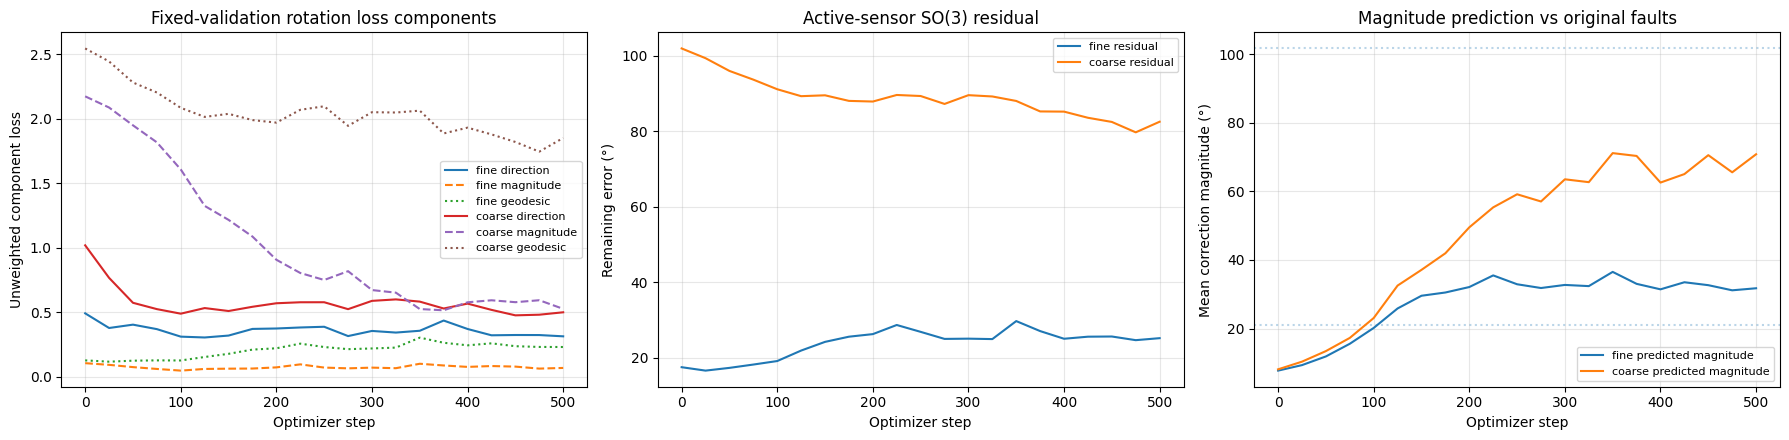

In [58]:
first, last = STOCHASTIC_ROTATION_HISTORY[0], STOCHASTIC_ROTATION_HISTORY[-1]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
steps = [row['step'] for row in STOCHASTIC_ROTATION_HISTORY]
for label in ('fine', 'coarse'):
    axes[0].plot(steps, [row[f'{label}_direction'] for row in STOCHASTIC_ROTATION_HISTORY], label=f'{label} direction')
    axes[0].plot(steps, [row[f'{label}_magnitude'] for row in STOCHASTIC_ROTATION_HISTORY], '--', label=f'{label} magnitude')
    axes[0].plot(steps, [row[f'{label}_geodesic'] for row in STOCHASTIC_ROTATION_HISTORY], ':', label=f'{label} geodesic')
    axes[1].plot(steps, [row[f'{label}_residual_deg'] for row in STOCHASTIC_ROTATION_HISTORY], label=f'{label} residual')
    axes[2].plot(steps, [row[f'{label}_pred_mag'] for row in STOCHASTIC_ROTATION_HISTORY], label=f'{label} predicted magnitude')
    axes[2].axhline(first[f'{label}_fault_deg'], linestyle=':', alpha=0.3)
axes[0].set(title='Fixed-validation rotation loss components', xlabel='Optimizer step', ylabel='Unweighted component loss')
axes[1].set(title='Active-sensor SO(3) residual', xlabel='Optimizer step', ylabel='Remaining error (°)')
axes[2].set(title='Magnitude prediction vs original faults', xlabel='Optimizer step', ylabel='Mean correction magnitude (°)')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [59]:
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation

TOKEN_SENSITIVITY_NUM_WINDOWS = min(BATCH_SIZE, 8)
TOKEN_SENSITIVITY_ROTATION_RAD = np.deg2rad(5.0)
TOKEN_SENSITIVITY_TRANSLATION_M = 0.02
TOKEN_SENSITIVITY_SEED = TRAIN_PAIR_SEED + 910000

token_sensitivity_indices = np.linspace(0, len(train_dataset) - 1, TOKEN_SENSITIVITY_NUM_WINDOWS, dtype=int)
token_sensitivity_base_window = collate_windows([train_dataset[int(index)] for index in token_sensitivity_indices])
token_sensitivity_base_window = window_batch_to(token_sensitivity_base_window, DEVICE, dtype=MODEL_DTYPE)

token_sensitivity_generator = make_augmentation_generator(TOKEN_SENSITIVITY_SEED)
token_sensitivity_window = context_augmentation_pipeline(token_sensitivity_base_window, generator=token_sensitivity_generator).augmented_window
token_sensitivity_truth = token_sensitivity_window.current_calibration

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z")

print("=" * 100)
print("SPATIAL CALIBRATION -> TOKEN SENSITIVITY")
print("=" * 100)
print(f"{'calibration':12s} {'component':10s} {'mean |Δx|':>14s} {'RMS Δx':>14s} {'max |Δx|':>14s} {'RMS/signal':>14s}")

for calibration_id, calibration_key in enumerate(CALIBRATION_KEYS):
    batch_size = token_sensitivity_truth[calibration_key].transform.shape[0]

    for component_index, component_name in enumerate(component_names):
        delta_xi_by_key = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_tau_by_key = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_xi_by_key[calibration_key][:, component_index] = TOKEN_SENSITIVITY_ROTATION_RAD if component_index < 3 else TOKEN_SENSITIVITY_TRANSLATION_M

        positive_calibration = apply_prior_perturbation(token_sensitivity_truth, delta_xi_by_key, delta_tau_by_key)
        negative_calibration = apply_prior_perturbation(token_sensitivity_truth, {key: -value for key, value in delta_xi_by_key.items()}, delta_tau_by_key)

        positive_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, positive_calibration), None)
        negative_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, negative_calibration), None)

        torch.testing.assert_close(positive_tokens.token_mask, negative_tokens.token_mask)
        torch.testing.assert_close(positive_tokens.calibration_ids, negative_tokens.calibration_ids)

        calibration_mask = positive_tokens.token_mask & (positive_tokens.calibration_ids == calibration_id)
        positive_measurements = positive_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        negative_measurements = negative_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        difference = positive_measurements - negative_measurements

        mean_abs = difference.abs().mean().item()
        rms = difference.square().mean().sqrt().item()
        maximum = difference.abs().max().item()
        signal_rms = (0.5 * (positive_measurements.square() + negative_measurements.square())).mean().sqrt().item()
        relative_rms = rms / max(signal_rms, 1e-12)

        print(f"{calibration_key:12s} {component_name:10s} {mean_abs:14.6e} {rms:14.6e} {maximum:14.6e} {relative_rms:14.6e}")

del token_sensitivity_base_window
del token_sensitivity_window
torch.cuda.empty_cache()

SPATIAL CALIBRATION -> TOKEN SENSITIVITY
calibration  component       mean |Δx|         RMS Δx       max |Δx|     RMS/signal
imu          phi_x        1.500774e-01   4.961924e-01   2.386278e+00   1.736864e-01
imu          phi_y        1.511438e-01   4.958833e-01   2.386277e+00   1.735781e-01
imu          phi_z        1.524938e-02   6.210872e-02   1.855107e+00   2.174043e-02
imu          rho_x        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_y        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_z        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
lidar        phi_x        5.239260e-04   1.362165e-03   2.975069e-02   8.602663e-03
lidar        phi_y        7.334019e-03   2.757858e-02   2.715913e-01   1.741707e-01
lidar        phi_z        7.404839e-03   2.758952e-02   2.715911e-01   1.742399e-01
lidar        rho_x        3.321525e-05   1.469670e-04   1.918331e-03   9.281607e-04
lidar        rho_y        3.292025e

## 14. Direct rotation-supervision epoch runner (single faulty prior)


In [60]:
def run_direct_epoch(loader, *, training: bool, pair_generator: torch.Generator, global_step: int):
    model.train(training)
    metric_sums, num_samples = {}, 0
    start_time = time.perf_counter()
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    for batch_index, base_window in enumerate(loader):
        base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
        faulted_window, fault_xi, _, _ = make_faulted_window(base_window, generator=pair_generator)
        loss, metrics = compute_direct_objective_66(faulted_window, fault_xi, training=training, active_optimizer=optimizer if training else None)
        if training:
            global_step += 1
        batch_size = next(iter(base_window.streams.values())).values.shape[0]
        accumulate_metrics(metric_sums, metrics, batch_size)
        num_samples += batch_size
        if training and PRINT_EVERY_BATCHES > 0 and (batch_index + 1) % PRINT_EVERY_BATCHES == 0:
            print(f'batch {batch_index + 1:5d}/{len(loader):5d} total={loss:.5f} '
                  f'geo={metrics["loss_rotation_geodesic"]:.4f} dir={metrics["loss_rotation_direction"]:.4f} mag={metrics["loss_rotation_magnitude"]:.4f} active_rot={metrics["active_initial_rotation_error_deg"]:.1f}°', flush=True)
        del faulted_window, fault_xi, base_window
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
    elapsed_s = time.perf_counter() - start_time
    epoch_metrics = normalize_metrics(metric_sums, num_samples)
    epoch_metrics['epoch_time_s'] = elapsed_s
    epoch_metrics['samples_per_s'] = num_samples / elapsed_s
    return epoch_metrics, global_step


## 15. Checkpoint paths and experiment snapshot


In [61]:
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'
METRICS_PATH = RUN_DIR / 'metrics.jsonl'
if INITIALIZATION_MODE == 'weights' and Path(INITIAL_WEIGHTS_CHECKPOINT).resolve() in (BEST_CHECKPOINT_PATH.resolve(), LAST_CHECKPOINT_PATH.resolve()):
    raise ValueError('Weights-only initialization must use a new RUN_NAME: source and output checkpoint paths coincide.')
EXPERIMENT_SNAPSHOT = {
    'run_name': RUN_NAME,
    'initialization_mode': INITIALIZATION_MODE,
    'initial_weights_checkpoint': str(INITIAL_WEIGHTS_CHECKPOINT) if INITIALIZATION_MODE == 'weights' else None,
    'resume_checkpoint': str(RESUME_CHECKPOINT) if INITIALIZATION_MODE == 'resume' else None,
    'calibration_keys': CALIBRATION_KEYS,
    'architecture': 'PooledCalibrationModel_3d_se3_log',
    'paired_prior_training': False,
    'supervision': 'direct_rotation_geodesic_direction_magnitude',
    'rotation_geodesic_weight': ROTATION_GEODESIC_WEIGHT,
    'rotation_direction_weight': ROTATION_DIRECTION_WEIGHT,
    'rotation_magnitude_weight': ROTATION_MAGNITUDE_WEIGHT,
    'active_rotation_weight': ACTIVE_ROTATION_WEIGHT,
    'healthy_rotation_weight': HEALTHY_ROTATION_WEIGHT,
    'rotation_supervision': ROTATION_SUPERVISION_MODE,
    'fine_student_t_max_deg': FINE_ROTATION_MAX_DEG,
    'fine_student_t_scale_deg': FINE_ROTATION_SCALE_DEG,
    'coarse_uniform_min_deg': COARSE_ROTATION_MIN_DEG,
    'coarse_uniform_max_deg': COARSE_ROTATION_MAX_DEG,
    'coarse_prior_probability': COARSE_PRIOR_PROBABILITY,
    'kaist_reference_tau_s': REFINED_TAU_BY_SENSOR_S,
    'frame_randomization': False,
    'true_calibration_augmentation': True,
    'measurement_noise': False,
    'numeric_calibration_context_in_pooler': False,
    'numeric_calibration_context_in_head': False,
}
train_pair_generator = make_augmentation_generator(TRAIN_PAIR_SEED)  # Historical generator checkpoint key retained for compatible resumption.


## 16. Initialize the full-training state (independent of stochastic preflight)

Model weights were already initialized in Cell 12, so the stochastic test and the full run use the same starting model. Only when `INITIALIZATION_MODE='resume'` does this cell restore the existing optimizer, scheduler, epoch, global step, and RNG/generator states. `scratch` and `weights` begin at epoch 0, with freshly created optimizer and scheduler.


In [62]:
start_epoch, global_step, best_validation_loss = 0, 0, float('inf')
if INITIALIZATION_MODE == 'resume':
    # A true resume, including optimizer/scheduler and train-sampler generator, is intentionally
    # different from the scratch defaults. Resume only from this architecture/run.
    checkpoint = load_training_checkpoint(
        RESUME_CHECKPOINT, model=model, optimizer=optimizer, scheduler=scheduler,
        map_location=DEVICE, restore_rng_state=True,
        generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator},
    )
    start_epoch = int(checkpoint.get('epoch', 0))
    global_step = int(checkpoint.get('global_step', 0))
    best_validation_loss = float(checkpoint.get('extra_state', {}).get('best_validation_loss', float('inf')))
    print('Restored model, optimizer, scheduler and RNG from:', RESUME_CHECKPOINT, '| epoch:', start_epoch, '| step:', global_step)
elif INITIALIZATION_MODE == 'weights':
    print('Weights-only initialization: model loaded in Cell 12; optimizer/scheduler are fresh, epoch=0, step=0.')
else:
    print('Scratch initialization: fresh model, optimizer/scheduler, epoch=0, step=0.')


Weights-only initialization: model loaded in Cell 12; optimizer/scheduler are fresh, epoch=0, step=0.


## 17. Full mixed-distribution training

`RUN_FULL_TRAINING` is independent of `RUN_STOCHASTIC_PAIR_TEST`. A new `scratch` or `weights` experiment starts at epoch 0 and writes new metrics/checkpoints under `RUN_NAME`; `resume` appends to that run using the saved optimizer/scheduler state. An existing output checkpoint cannot be silently overwritten in a new run.


In [63]:
torch.cuda.empty_cache()

In [64]:
history = []
if RUN_FULL_TRAINING and REQUIRE_STOCHASTIC_GATE and ROTATION_STOCHASTIC_GATE_PASSED is not True:
    raise RuntimeError('Split-rotation stochastic gate requested but not passed. Disable REQUIRE_STOCHASTIC_GATE or rerun the diagnostic.')
if RUN_FULL_TRAINING:
    if INITIALIZATION_MODE != 'resume' and (BEST_CHECKPOINT_PATH.exists() or LAST_CHECKPOINT_PATH.exists()):
        raise FileExistsError(f'Fresh training would overwrite checkpoints in {RUN_DIR}. Choose a new RUN_NAME, or INITIALIZATION_MODE="resume".')
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    with MetricsLogger(METRICS_PATH, append=(INITIALIZATION_MODE == 'resume')) as logger:
        if INITIALIZATION_MODE != 'resume':
            logger.log_config(model_config, name="model_config")
            logger.log_config(context_augmentation_config, name="context_augmentation_config")
            logger.log_config(fine_prior_config, name="fine_prior_config")
            logger.log_config(coarse_prior_config, name="coarse_prior_config")
            logger.log_config(
                {
                    "device": str(DEVICE),
                    "batch_size": BATCH_SIZE,
                    "window_duration_s": WINDOW_DURATION_S,
                    "window_stride_s": WINDOW_STRIDE_S,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "train_sequences": TRAIN_NAMES,
                    "validation_sequences": VAL_NAMES,
                    "test_sequences": TEST_NAMES,
                    **EXPERIMENT_SNAPSHOT,
                },
                name="experiment",
            )

        for epoch in range(start_epoch, NUM_EPOCHS):
            print()
            print("=" * 80)
            print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")

            train_metrics, global_step = run_direct_epoch(train_loader, training=True, pair_generator=train_pair_generator, global_step=global_step)

            # Regenerate identical validation physical augmentations and faults each epoch.
            val_pair_generator = make_augmentation_generator(VALIDATION_PAIR_SEED)
            val_metrics, _ = run_direct_epoch(val_loader, training=False, pair_generator=val_pair_generator, global_step=global_step)

            scheduler.step(val_metrics["loss_total"])
            learning_rate = optimizer.param_groups[0]["lr"]

            row = {
                "epoch": epoch + 1,
                "global_step": global_step,
                "learning_rate": learning_rate,
                **{f"train/{key}": value for key, value in train_metrics.items()},
                **{f"val/{key}": value for key, value in val_metrics.items()},
            }
            history.append(row)

            logger.log_metrics({**train_metrics, "learning_rate": learning_rate}, split="train", epoch=epoch + 1, step=global_step)
            logger.log_metrics(val_metrics, split="validation", epoch=epoch + 1, step=global_step)

            print(
                f"train total={train_metrics['loss_total']:.5f} geo={train_metrics['loss_rotation_geodesic']:.5f} dir={train_metrics['loss_rotation_direction']:.5f} mag={train_metrics['loss_rotation_magnitude']:.5f} rot={train_metrics['active_initial_rotation_error_deg']:.1f}° | "
                f"val total={val_metrics['loss_total']:.5f} geo={val_metrics['loss_rotation_geodesic']:.5f} dir={val_metrics['loss_rotation_direction']:.5f} mag={val_metrics['loss_rotation_magnitude']:.5f} rot={val_metrics['active_initial_rotation_error_deg']:.1f}° | "
                f"lr={learning_rate:.3e}"
            )

            if val_metrics["loss_total"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_total"]
                save_training_checkpoint(
                    BEST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss},
                )
                print("Saved new best checkpoint.")

            if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch + 1 == NUM_EPOCHS:
                save_training_checkpoint(
                    LAST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss},
                )
                print("Saved last checkpoint.")
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print('Full training disabled by RUN_FULL_TRAINING=False; stochastic gate is advisory by default.')



Epoch 1/200
train total=10.14383 geo=1.61343 dir=0.42971 mag=1.30994 rot=63.3° | val total=9.18185 geo=1.55284 dir=0.41531 mag=0.96153 rot=63.9° | lr=7.500e-05
Saved new best checkpoint.

Epoch 2/200
train total=8.36571 geo=1.43241 dir=0.40037 mag=0.74859 rot=61.1° | val total=7.97287 geo=1.40373 dir=0.39910 mag=0.58720 rot=60.5° | lr=7.500e-05
Saved new best checkpoint.

Epoch 3/200
train total=8.04370 geo=1.43067 dir=0.41556 mag=0.51336 rot=60.4° | val total=7.58372 geo=1.36999 dir=0.40301 mag=0.40684 rot=58.4° | lr=7.500e-05
Saved new best checkpoint.
Saved last checkpoint.

Epoch 4/200
train total=7.65361 geo=1.36925 dir=0.40997 mag=0.40772 rot=58.9° | val total=7.36165 geo=1.33427 dir=0.39839 mag=0.35463 rot=56.6° | lr=7.500e-05
Saved new best checkpoint.

Epoch 5/200
train total=7.35433 geo=1.33870 dir=0.39196 mag=0.37868 rot=57.1° | val total=7.22387 geo=1.34084 dir=0.38721 mag=0.33504 rot=56.8° | lr=7.500e-05
Saved new best checkpoint.

Epoch 6/200
train total=7.28231 geo=1.35

KeyboardInterrupt: 

## 18. Rotation direction / magnitude / geodesic training curves


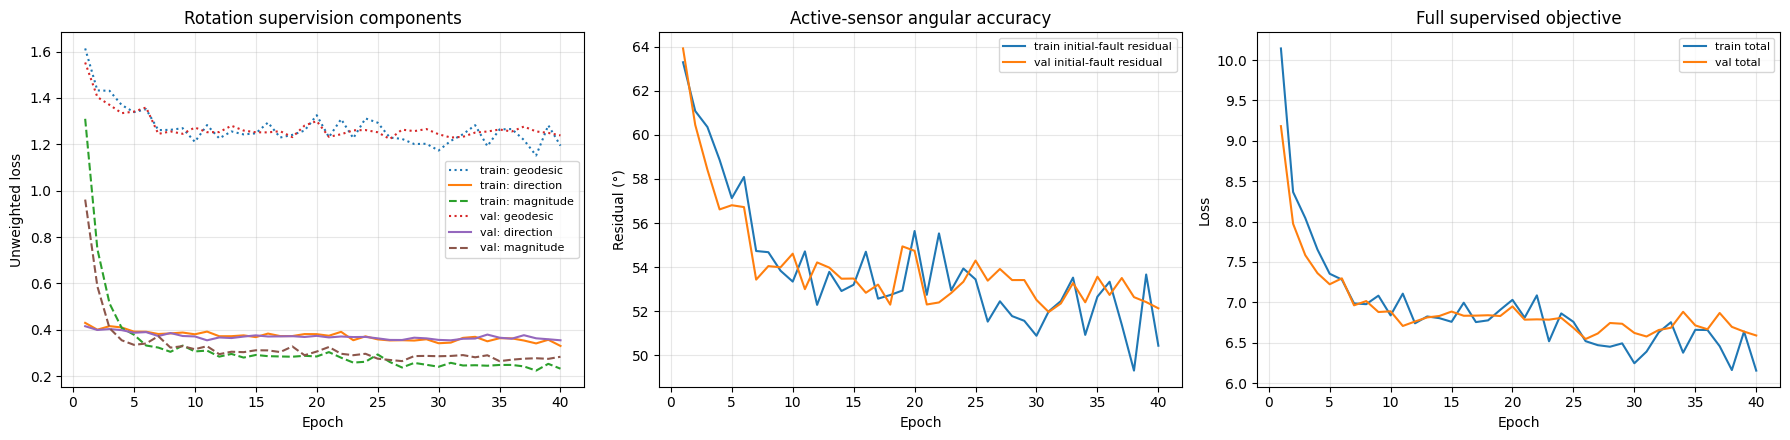

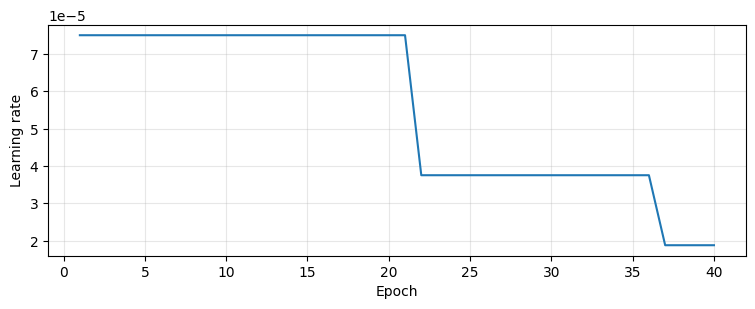

In [65]:
if history:
    epochs = [row['epoch'] for row in history]
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for split in ('train', 'val'):
        for component, linestyle in (('loss_rotation_geodesic', ':'), ('loss_rotation_direction', '-'), ('loss_rotation_magnitude', '--')):
            axes[0].plot(epochs, [row[f'{split}/{component}'] for row in history], linestyle=linestyle, label=f'{split}: {component.replace("loss_rotation_", "")}')
        axes[1].plot(epochs, [row[f'{split}/active_initial_rotation_error_deg'] for row in history], label=f'{split} initial-fault residual')
        axes[2].plot(epochs, [row[f'{split}/loss_total'] for row in history], label=f'{split} total')
    axes[0].set(title='Rotation supervision components', xlabel='Epoch', ylabel='Unweighted loss')
    axes[1].set(title='Active-sensor angular accuracy', xlabel='Epoch', ylabel='Residual (°)')
    axes[2].set(title='Full supervised objective', xlabel='Epoch', ylabel='Loss')
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.figure(figsize=(9, 3))
    plt.plot(epochs, [row['learning_rate'] for row in history])
    plt.xlabel('Epoch')
    plt.ylabel('Learning rate')
    plt.grid(alpha=0.3)
    plt.show()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()


## 19. Evaluate the best checkpoint


In [66]:
if BEST_CHECKPOINT_PATH.exists():
    best_checkpoint = load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    test_pair_generator = make_augmentation_generator(TEST_PAIR_SEED)
    test_metrics, _ = run_direct_epoch(test_loader, training=False, pair_generator=test_pair_generator, global_step=global_step)

    print("Best checkpoint epoch:", best_checkpoint.get("epoch"))
    print("Test metrics:")
    for key in sorted(test_metrics):
        print(f"  {key}: {test_metrics[key]:.6f}")
else:
    print("No best checkpoint exists yet.")


Best checkpoint epoch: 26
Test metrics:
  active_axis_cos: 0.630126
  active_initial_axis_cos: 0.630126
  active_initial_fault_deg: 76.467125
  active_initial_predicted_magnitude_deg: 67.945834
  active_initial_rotation_error_deg: 55.976532
  active_predicted_magnitude_deg: 67.945834
  active_rotation_error_deg: 55.976532
  active_target_magnitude_deg: 76.467128
  epoch_time_s: 59.455772
  grad_norm_before_clip: nan
  imu/loss_rotation_direction: 0.267379
  imu/loss_rotation_geodesic: 0.429567
  imu/loss_rotation_magnitude: 0.131335
  imu/loss_time_offset: 1.271196
  imu/loss_translation: 2.497366
  imu/rotation_error_deg: 18.220047
  imu/time_offset_error_ms: 21.817176
  imu/translation_error_cm: 5.714221
  lidar/loss_rotation_direction: 0.448705
  lidar/loss_rotation_geodesic: 0.616248
  lidar/loss_rotation_magnitude: 0.271897
  lidar/loss_time_offset: 0.397303
  lidar/loss_translation: 1.932108
  lidar/rotation_error_deg: 24.058396
  lidar/time_offset_error_ms: 12.301462
  lidar/tra

## 20. Select held-out windows for detailed visualization


In [67]:
VIS_SEQUENCE_NAME = "Urban38"
VIS_START_WINDOW = 0
VIS_NUM_WINDOWS = 100
VIS_BATCH_SIZE = 16

sequence_indices = [index for index in range(len(test_dataset)) if test_dataset.sequence_name_for_window(index) == VIS_SEQUENCE_NAME]

if not sequence_indices:
    raise ValueError(f"Sequence {VIS_SEQUENCE_NAME!r} is not present in test_dataset.")

selected_indices = sequence_indices[VIS_START_WINDOW : VIS_START_WINDOW + VIS_NUM_WINDOWS]

print("Sequence:", VIS_SEQUENCE_NAME)
print("Selected windows:", len(selected_indices))
print("Dataset indices:", selected_indices[0], "...", selected_indices[-1])


Sequence: Urban38
Selected windows: 100
Dataset indices: 0 ... 99


## 21. Collect deterministic paired predictions


In [68]:
def collect_paired_predictions(dataset, indices, *, batch_size, pair_seed):
    model.eval()
    pair_generator = make_augmentation_generator(pair_seed)

    collected = {
        calibration_key: {
            "positive_true_xi": [],
            "positive_predicted_xi": [],
            "positive_true_tau": [],
            "positive_predicted_tau": [],
            "negative_true_xi": [],
            "negative_predicted_xi": [],
            "negative_true_tau": [],
            "negative_predicted_tau": [],
        }
        for calibration_key in CALIBRATION_KEYS
    }

    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start : start + batch_size]
            base_window = collate_windows([dataset[index] for index in batch_indices])
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)

            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator)
            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)

            for calibration_key in CALIBRATION_KEYS:
                positive_true_xi, positive_true_tau = correction_target(positive_window, calibration_key)
                negative_true_xi, negative_true_tau = correction_target(negative_window, calibration_key)

                positive_prediction = positive_result.model_output.predictions[calibration_key]
                negative_prediction = negative_result.model_output.predictions[calibration_key]

                collected[calibration_key]["positive_true_xi"].append(positive_true_xi.detach().cpu())
                collected[calibration_key]["positive_predicted_xi"].append(positive_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["positive_true_tau"].append(positive_true_tau.detach().cpu())
                collected[calibration_key]["positive_predicted_tau"].append(positive_prediction.delta_tau.detach().cpu())

                collected[calibration_key]["negative_true_xi"].append(negative_true_xi.detach().cpu())
                collected[calibration_key]["negative_predicted_xi"].append(negative_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["negative_true_tau"].append(negative_true_tau.detach().cpu())
                collected[calibration_key]["negative_predicted_tau"].append(negative_prediction.delta_tau.detach().cpu())

    for calibration_key in CALIBRATION_KEYS:
        for field_name in collected[calibration_key]:
            collected[calibration_key][field_name] = torch.cat(collected[calibration_key][field_name], dim=0).numpy()

    return collected


if BEST_CHECKPOINT_PATH.exists():
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

visualization_results = collect_paired_predictions(test_dataset, selected_indices, batch_size=VIS_BATCH_SIZE, pair_seed=VISUALIZATION_PAIR_SEED)


## 22. True vs predicted correction over windows


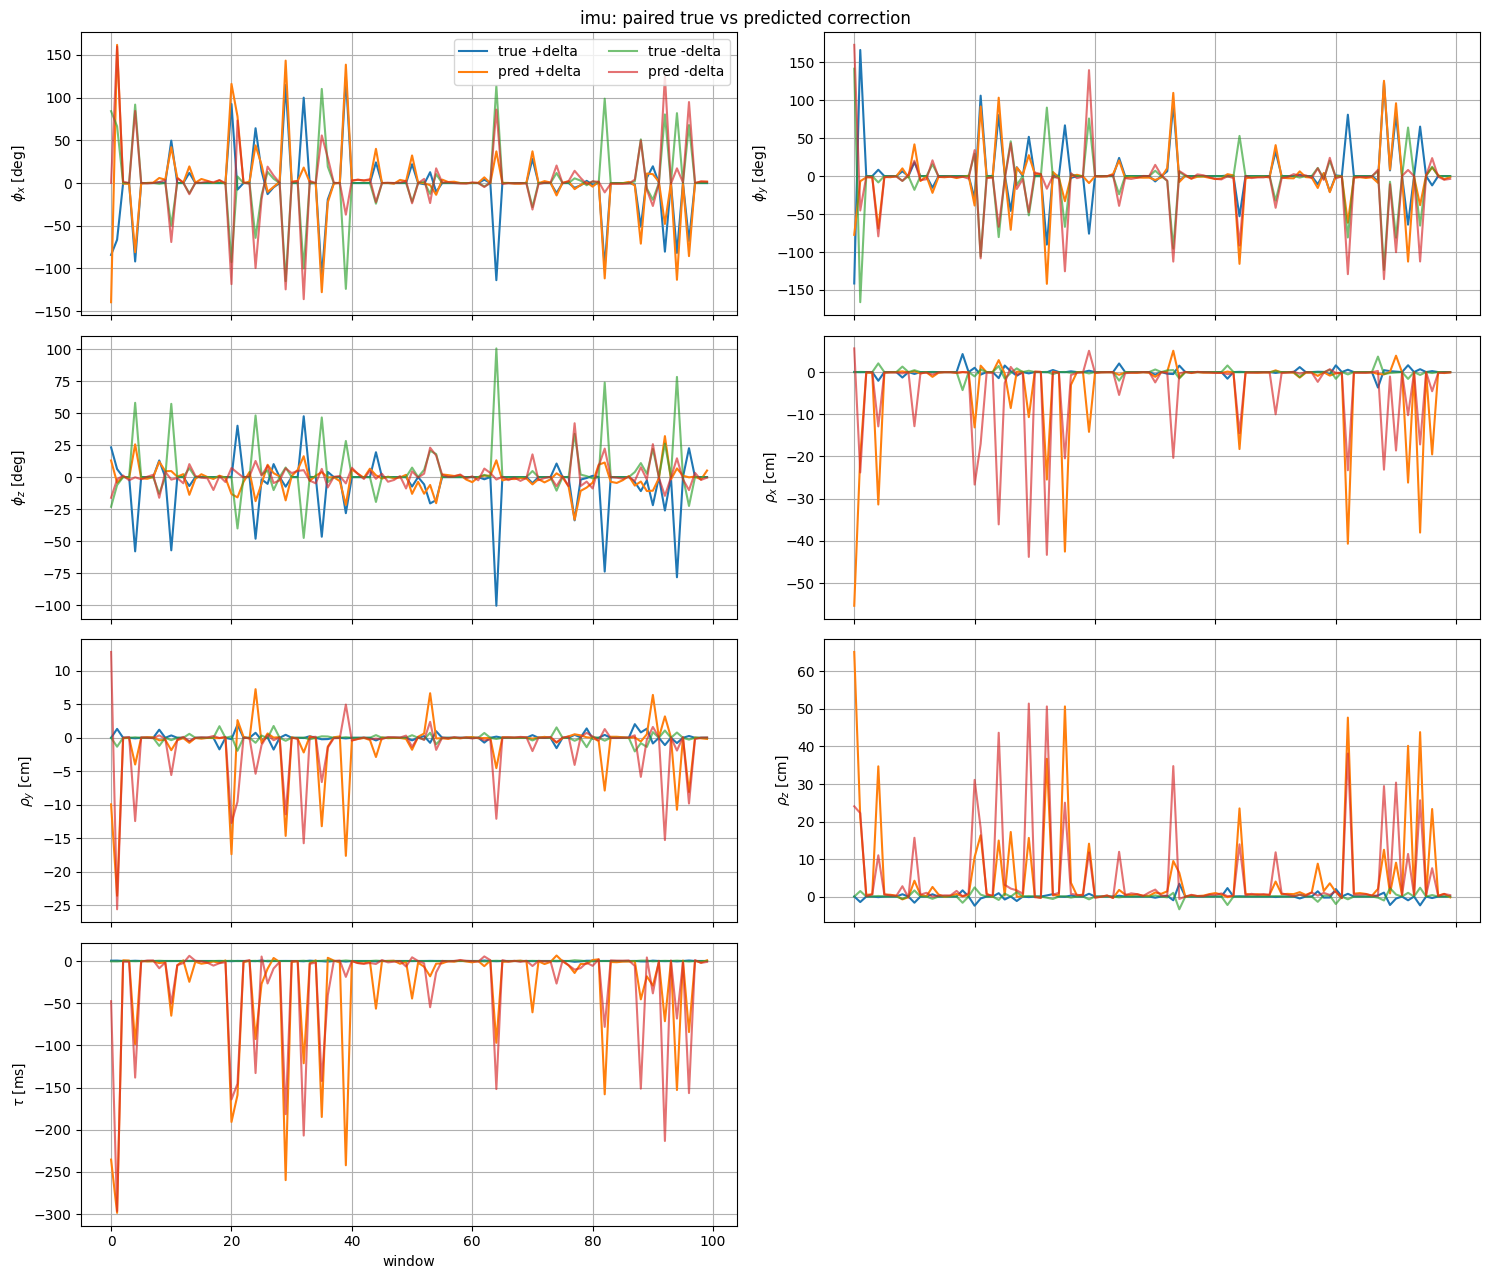

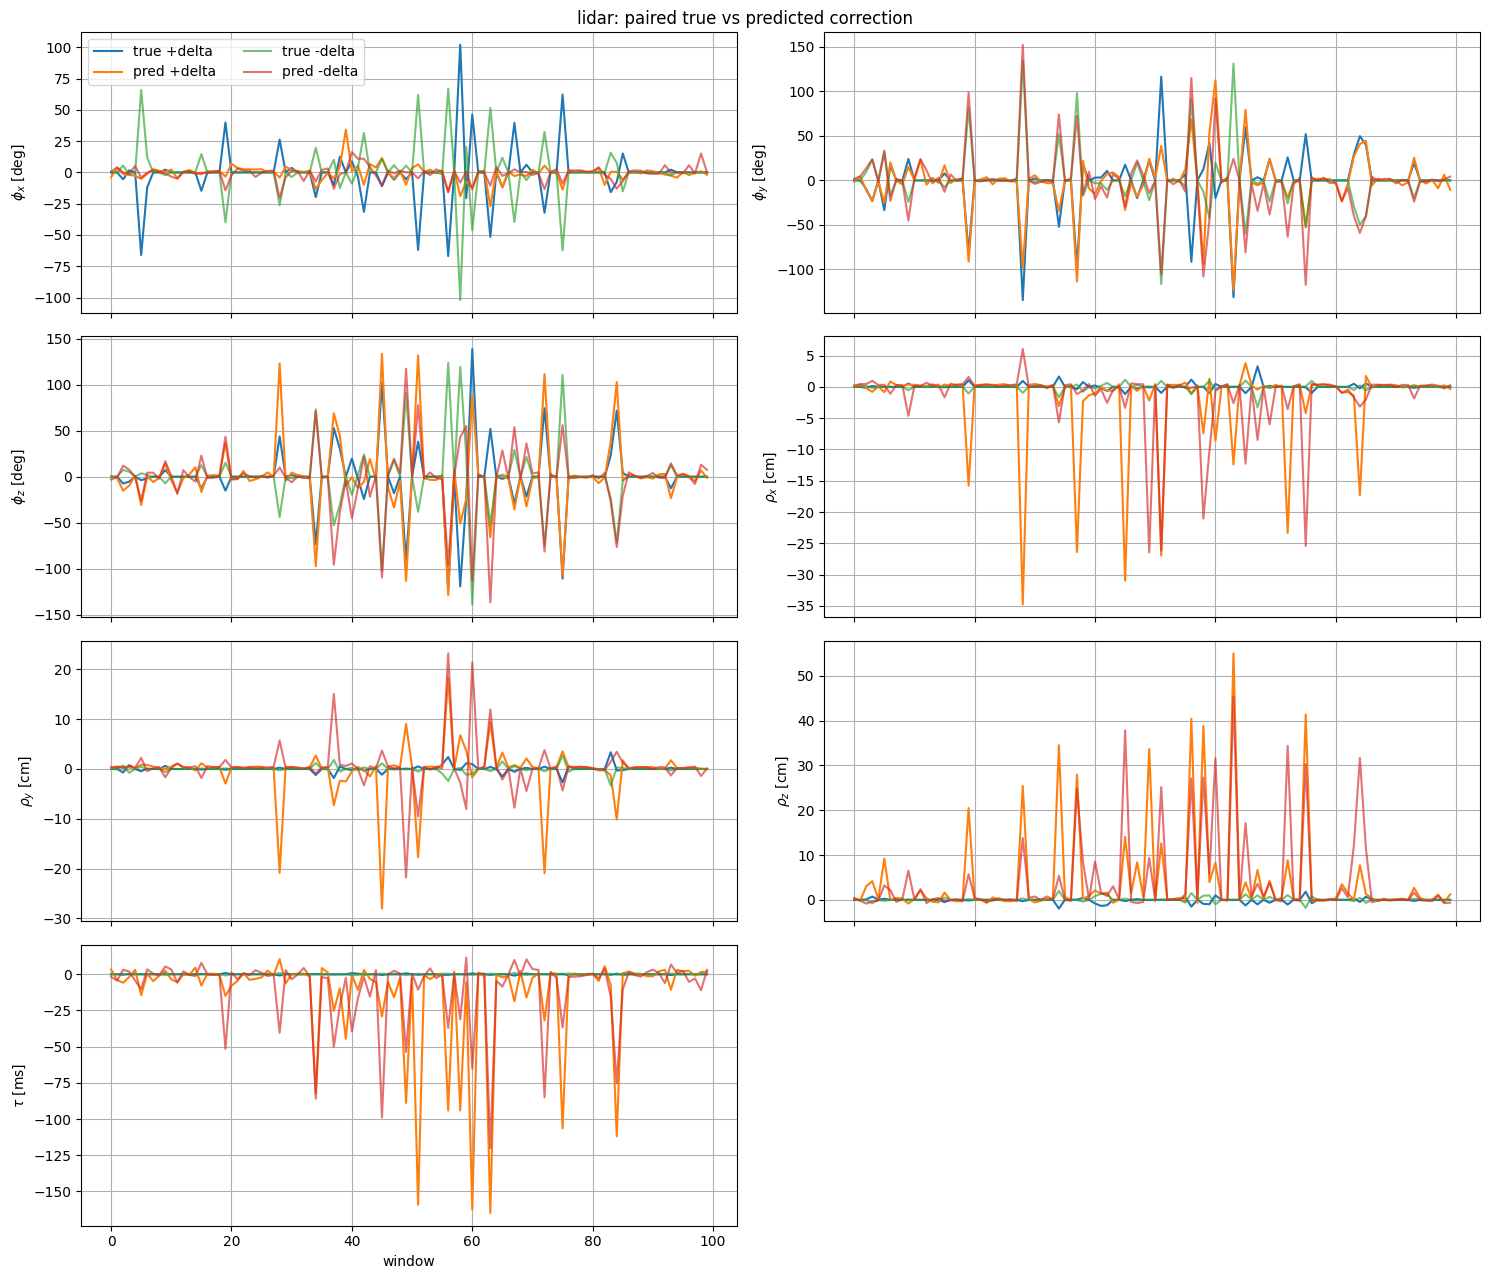

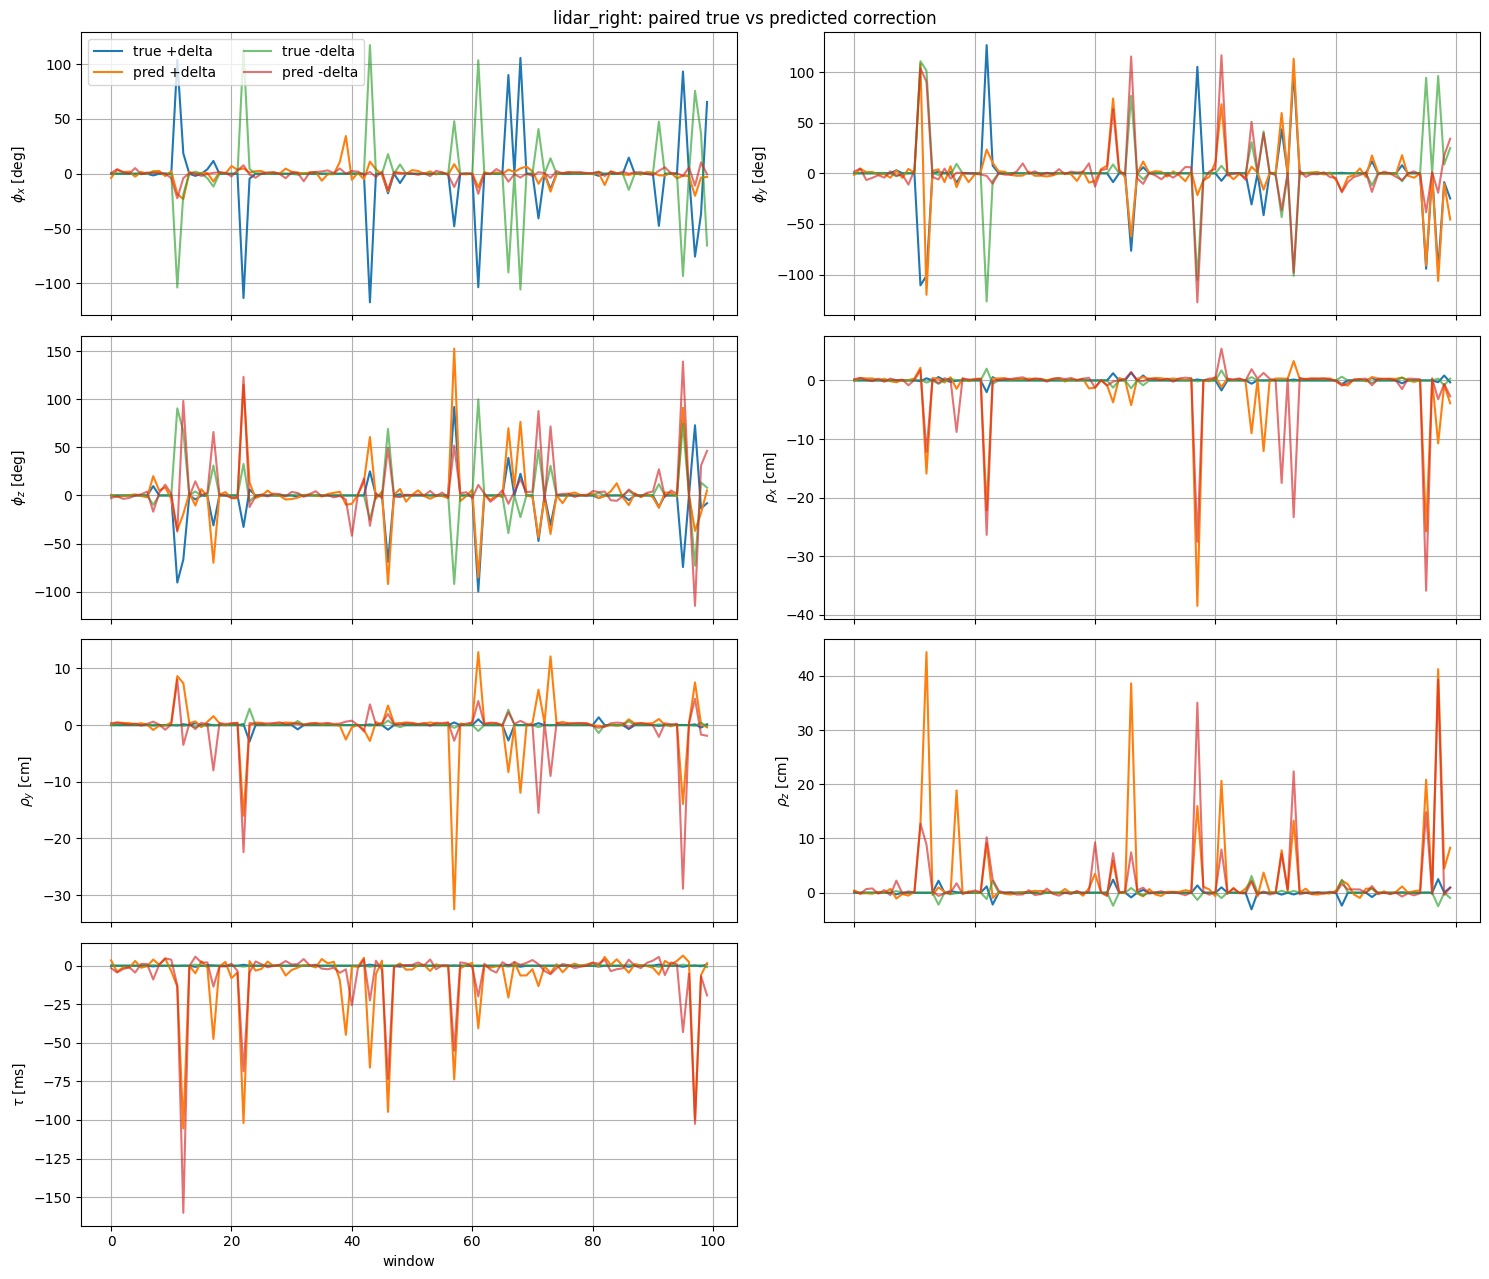

In [69]:
def physical_correction_values(xi, tau):
    return np.column_stack([np.rad2deg(xi[:, :3]), 100.0 * xi[:, 3:], 1000.0 * tau.reshape(-1)])


def plot_paired_true_vs_predicted(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")
    x = np.arange(len(positive_true))

    fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True)
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        ax.plot(x, positive_true[:, component_index], label="true +delta")
        ax.plot(x, positive_predicted[:, component_index], label="pred +delta")
        ax.plot(x, negative_true[:, component_index], label="true -delta", alpha=0.65)
        ax.plot(x, negative_predicted[:, component_index], label="pred -delta", alpha=0.65)
        ax.set_ylabel(f"{component_names[component_index]} [{units[component_index]}]")
        ax.grid(True)

        if component_index == 0:
            ax.legend(ncol=2)

    axes[6].set_xlabel("window")
    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: paired true vs predicted correction")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_paired_true_vs_predicted(visualization_results, calibration_key)


## 23. Combined true-vs-predicted scatter


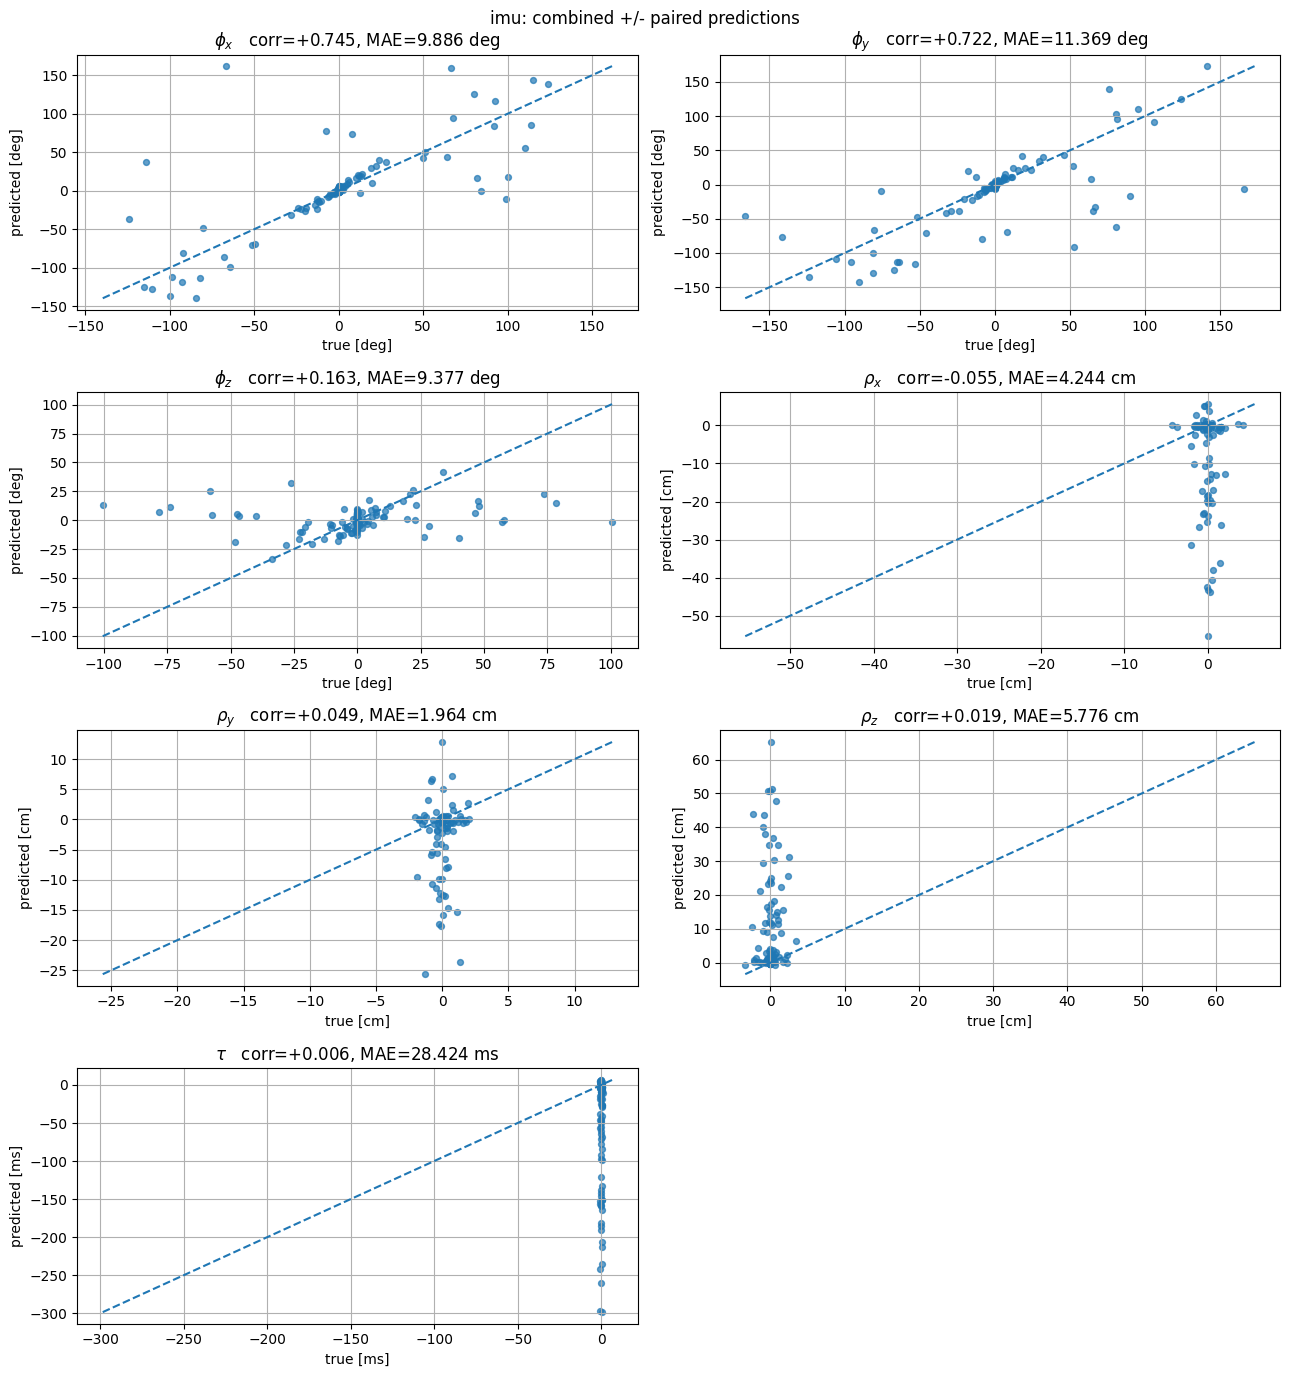

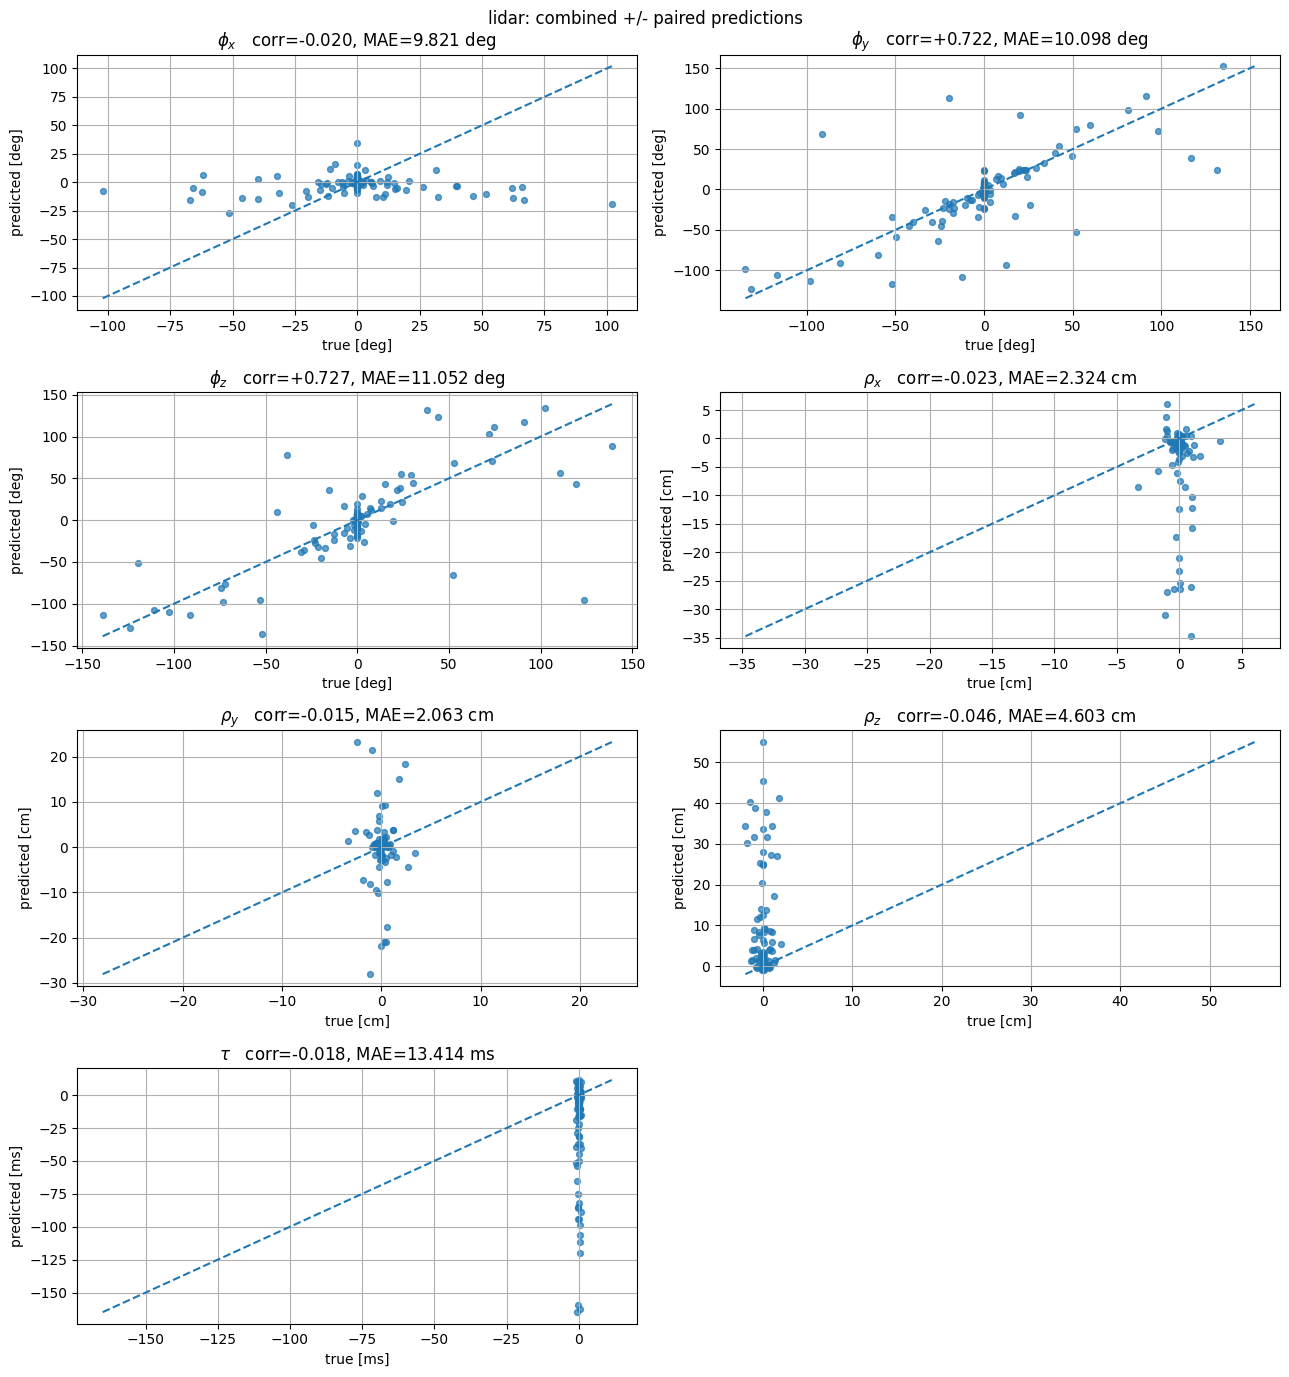

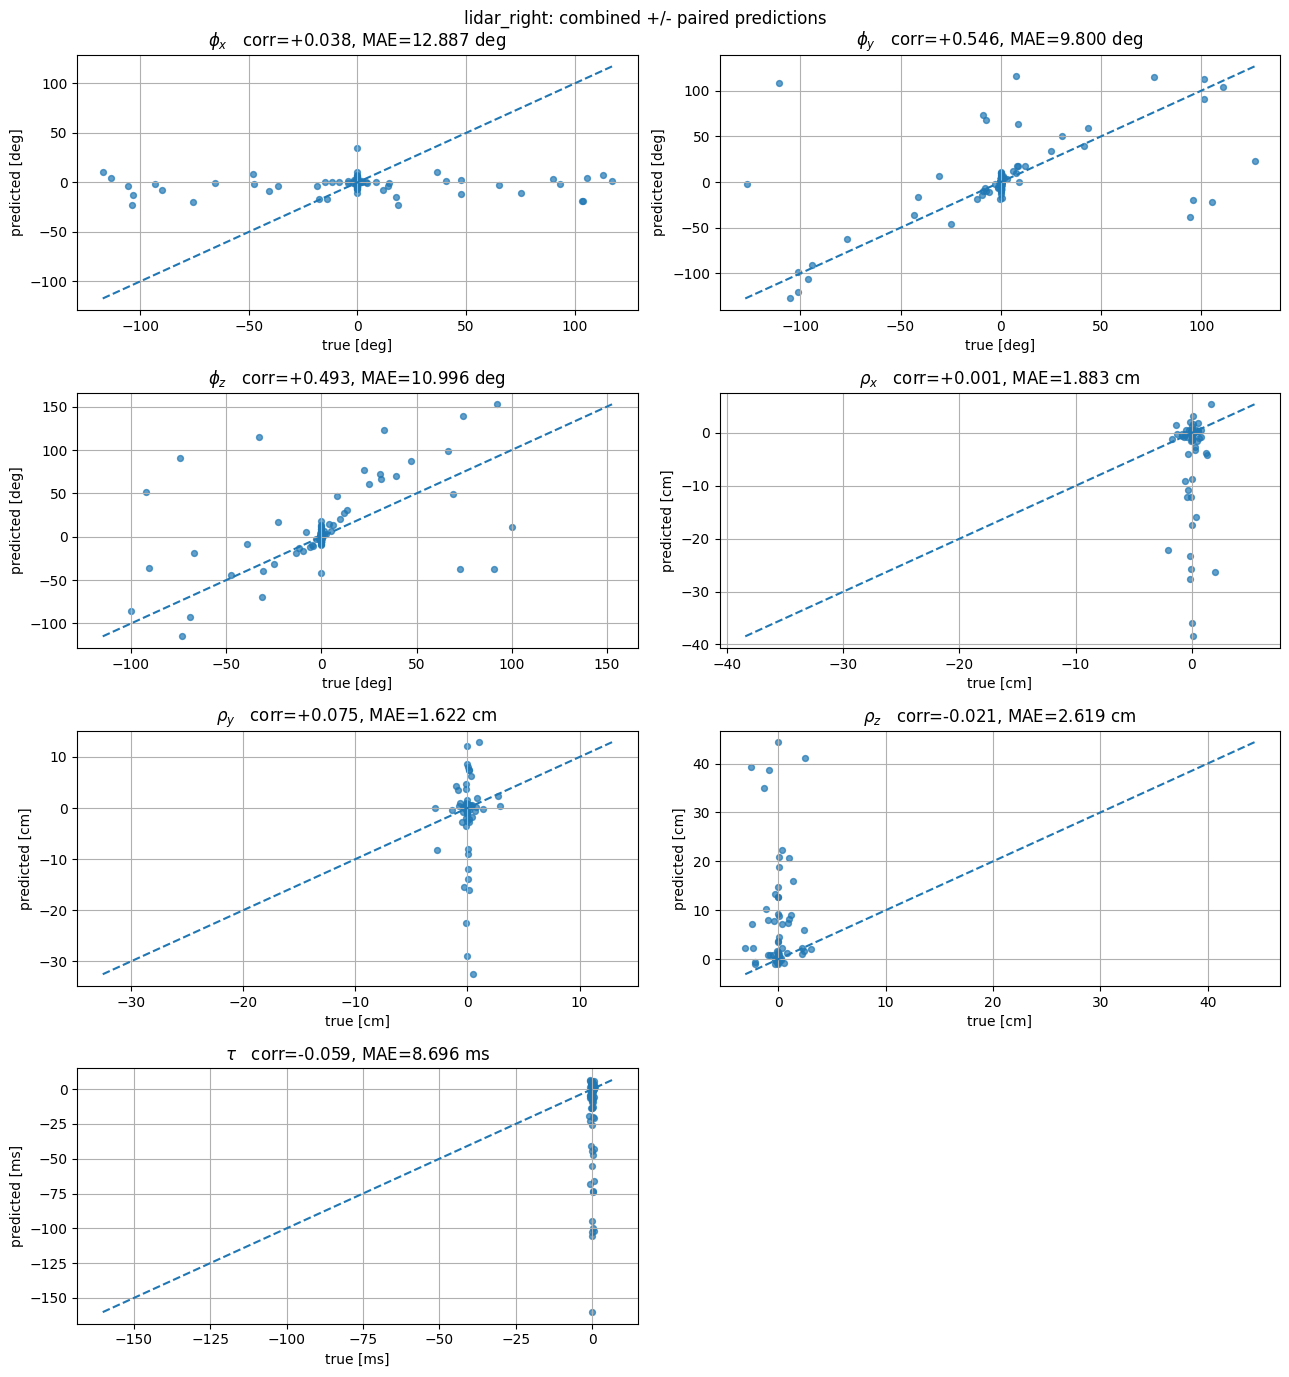

In [70]:
def plot_combined_true_vs_predicted_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]

        minimum = min(component_truth.min(), component_prediction.min())
        maximum = max(component_truth.max(), component_prediction.max())
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        mae = np.mean(np.abs(component_prediction - component_truth))

        ax.scatter(component_truth, component_prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"true [{units[component_index]}]")
        ax.set_ylabel(f"predicted [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}, MAE={mae:.3f} {units[component_index]}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: combined +/- paired predictions")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_combined_true_vs_predicted_scatter(visualization_results, calibration_key)


## 24. Legacy ±pair difference scatter (evaluation only)

These plots compare how the split-supervised model behaves on historical ±δ test pairs; the **training loss does not contain this paired term**. In particular, Euclidean rotation-vector scatter near ±π has branch-cut artifacts. Use the exact-angle SO(3) plots later in the notebook for physical errors.


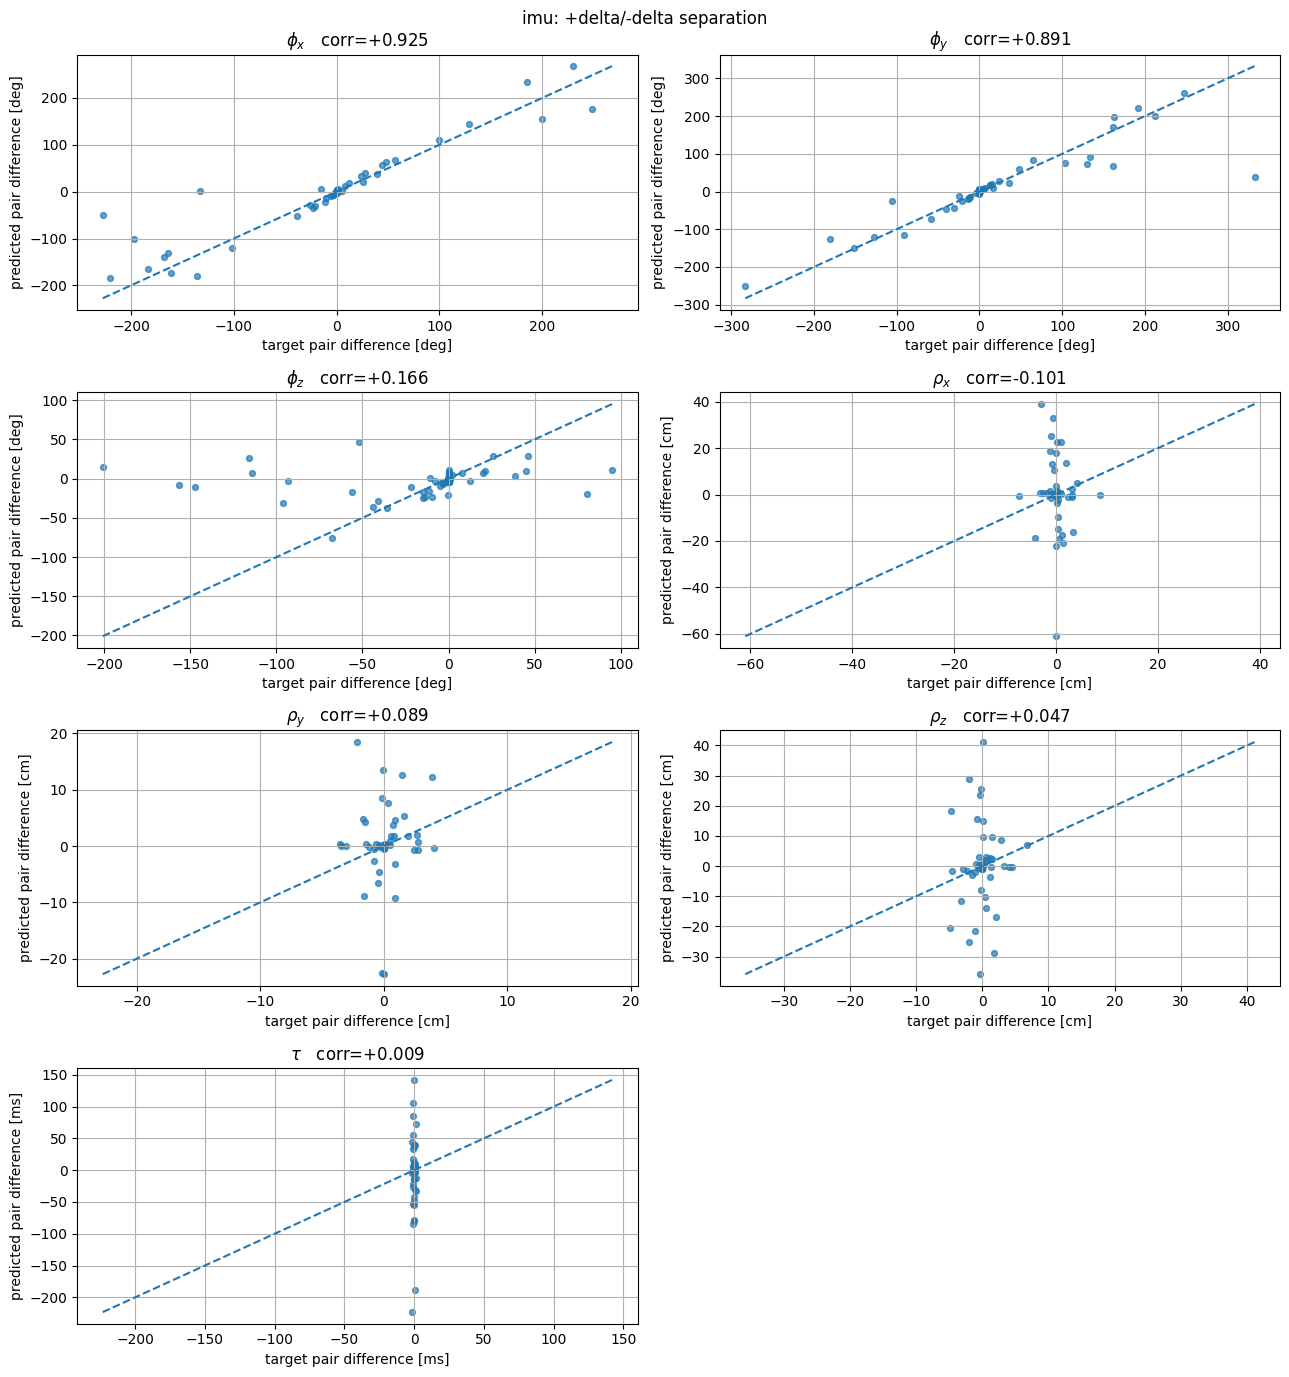

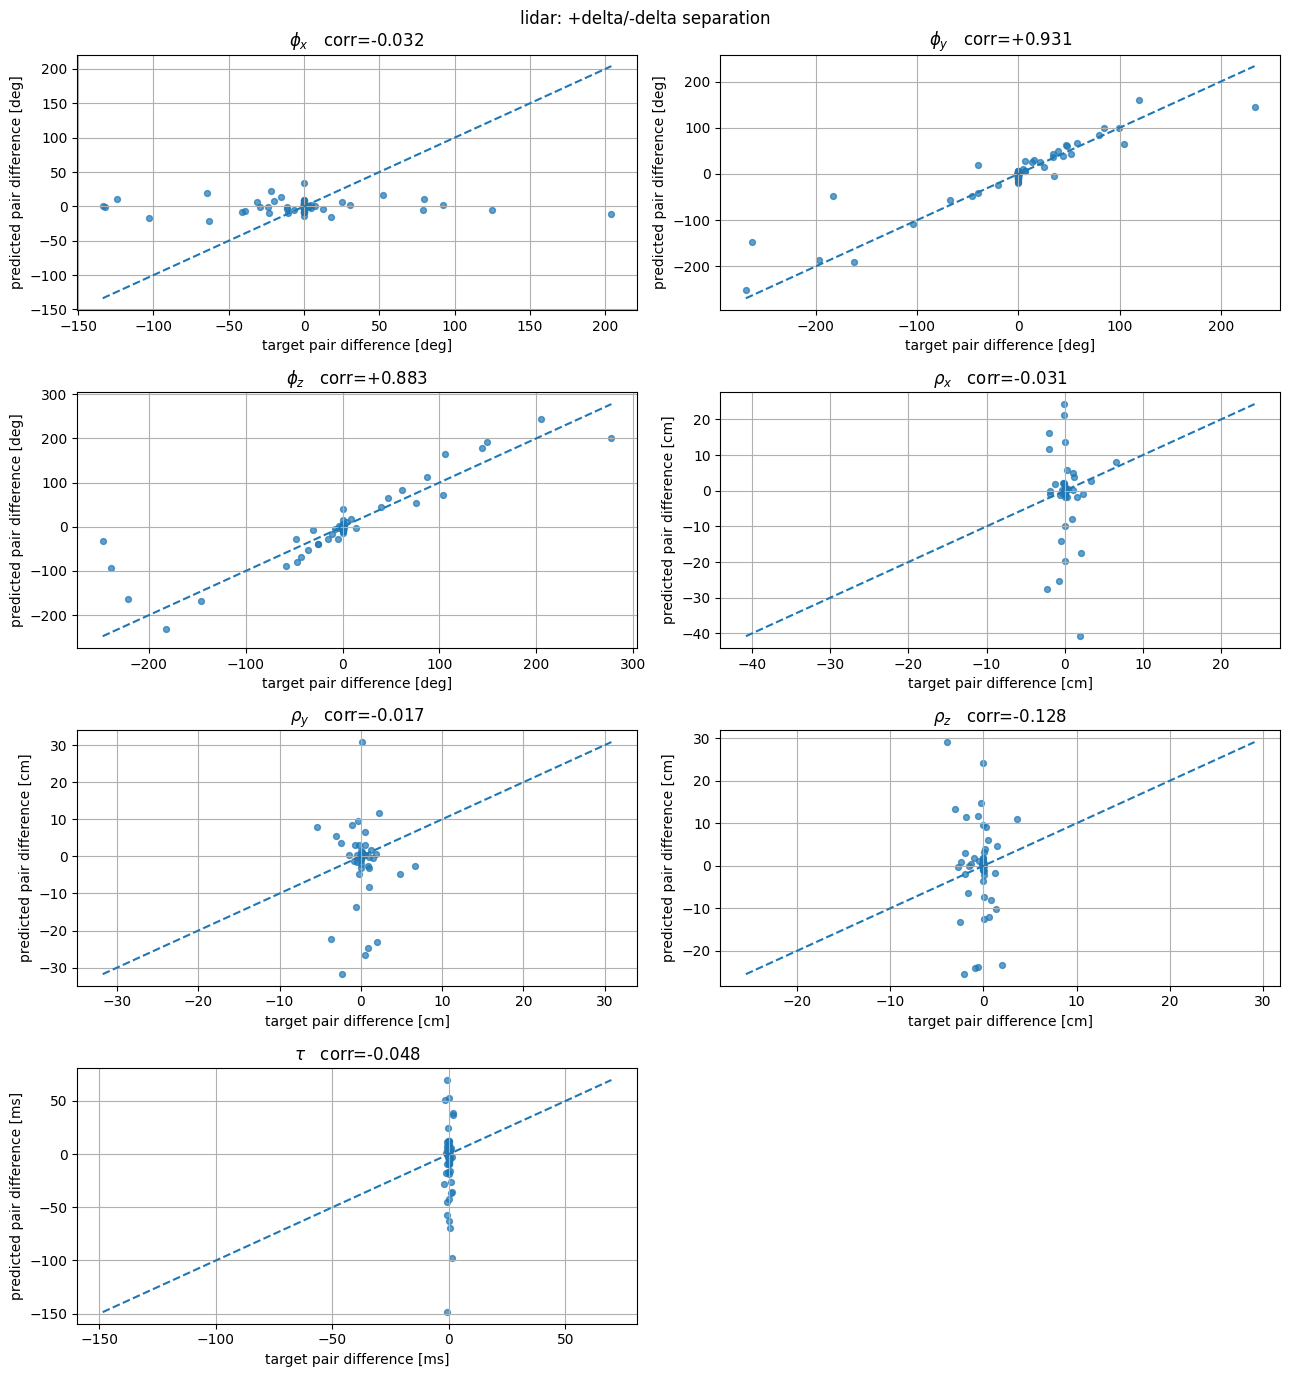

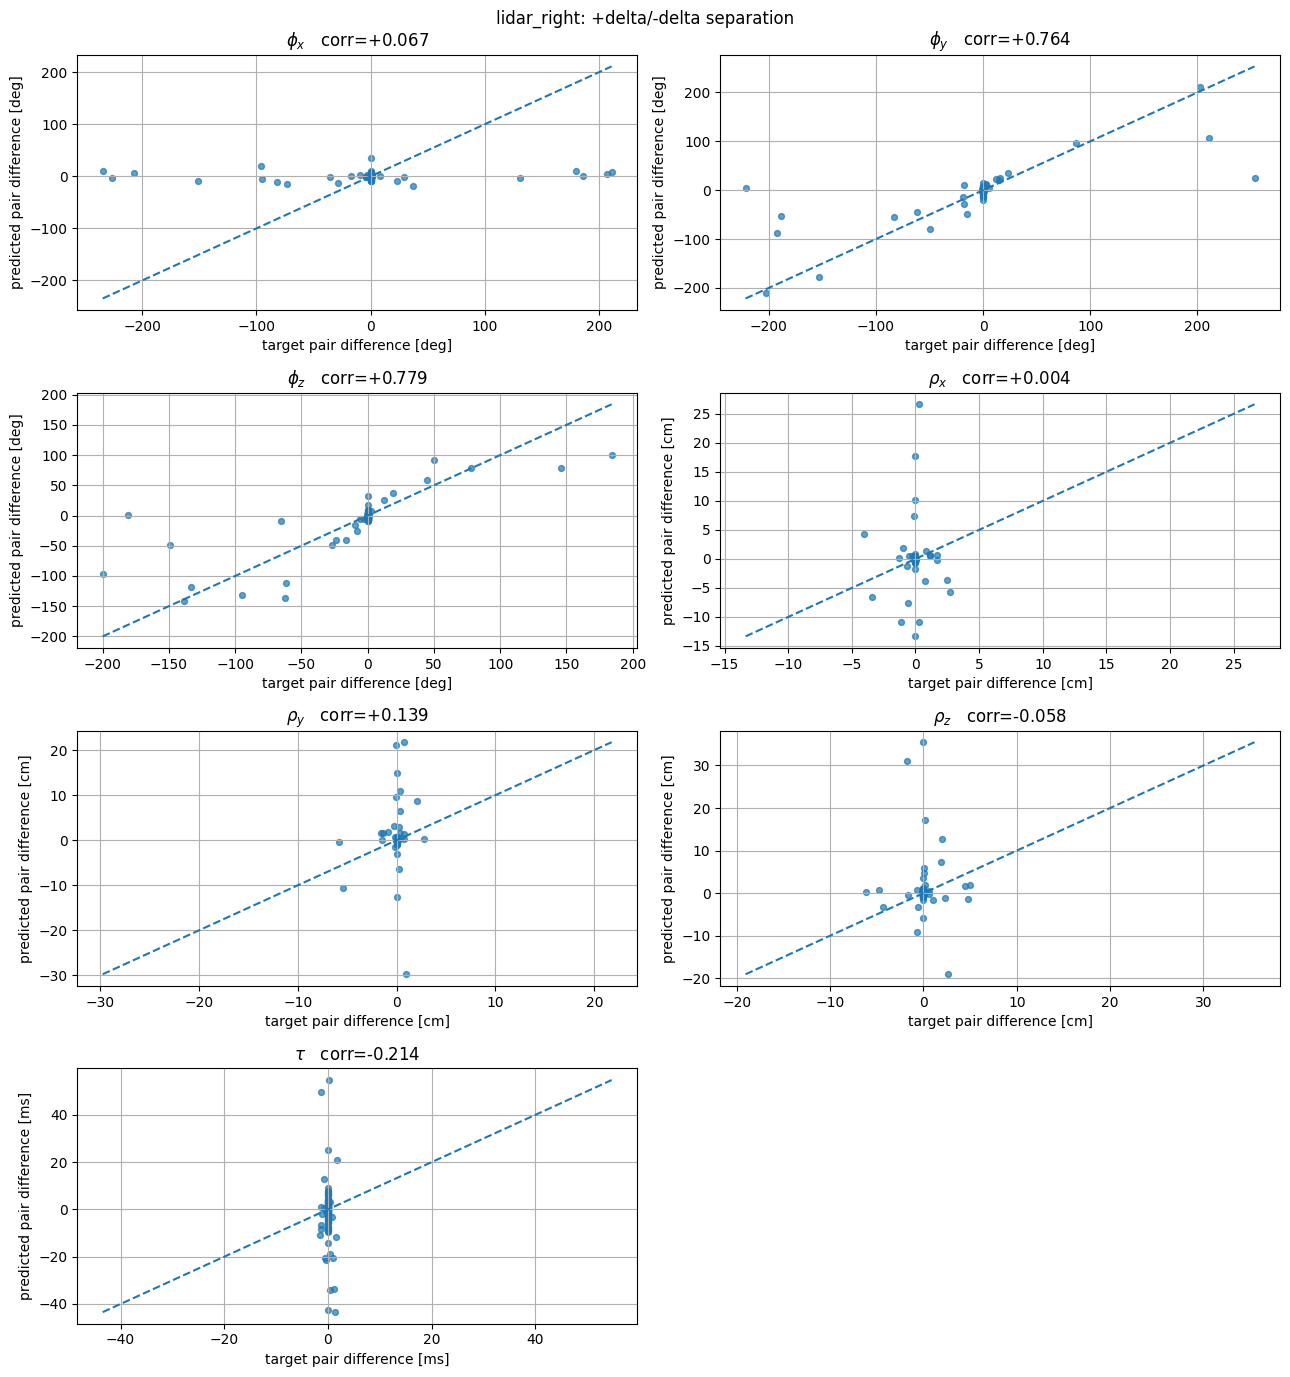

In [71]:
def plot_pair_difference_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        truth = target_difference[:, component_index]
        prediction = predicted_difference[:, component_index]

        minimum = min(truth.min(), prediction.min())
        maximum = max(truth.max(), prediction.max())
        correlation = np.corrcoef(truth, prediction)[0, 1] if np.std(truth) > 0.0 and np.std(prediction) > 0.0 else np.nan

        ax.scatter(truth, prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"target pair difference [{units[component_index]}]")
        ax.set_ylabel(f"predicted pair difference [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: +delta/-delta separation")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_pair_difference_scatter(visualization_results, calibration_key)


## 25. Numerical paired-prediction summary


In [72]:
def print_paired_prediction_summary(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)
    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    print(calibration_key)
    print(f"{'component':8s} {'MAE':>12s} {'corr':>10s} {'pred std':>12s} {'pair corr':>12s} {'pair MAE':>12s}")

    for component_index, component_name in enumerate(component_names):
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]
        difference_truth = target_difference[:, component_index]
        difference_prediction = predicted_difference[:, component_index]

        mae = np.mean(np.abs(component_prediction - component_truth))
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        pair_correlation = np.corrcoef(difference_truth, difference_prediction)[0, 1] if np.std(difference_truth) > 0.0 and np.std(difference_prediction) > 0.0 else np.nan
        pair_mae = np.mean(np.abs(difference_prediction - difference_truth))

        print(
            f"{component_name:8s} "
            f"{mae:9.4f} {units[component_index]:3s} "
            f"{correlation:+10.4f} "
            f"{np.std(component_prediction):12.4f} "
            f"{pair_correlation:+12.4f} "
            f"{pair_mae:9.4f} {units[component_index]:3s}"
        )

    print()


for calibration_key in CALIBRATION_KEYS:
    print_paired_prediction_summary(visualization_results, calibration_key)


imu
component          MAE       corr     pred std    pair corr     pair MAE
phi_x       9.8856 deg    +0.7453      40.3605      +0.9250   10.5272 deg
phi_y      11.3691 deg    +0.7223      39.2407      +0.8914   10.4190 deg
phi_z       9.3773 deg    +0.1630       8.4374      +0.1664   16.3890 deg
rho_x       4.2435 cm     -0.0550       9.8166      -0.1010    4.8177 cm 
rho_y       1.9635 cm     +0.0488       4.5202      +0.0887    2.1016 cm 
rho_z       5.7765 cm     +0.0189      11.9659      +0.0469    4.3912 cm 
tau        28.4242 ms     +0.0056      60.9304      +0.0088   18.2528 ms 

lidar
component          MAE       corr     pred std    pair corr     pair MAE
phi_x       9.8213 deg    -0.0197       6.0899      -0.0324   18.5485 deg
phi_y      10.0981 deg    +0.7223      34.1886      +0.9314    9.9971 deg
phi_z      11.0516 deg    +0.7267      37.3820      +0.8832   13.8213 deg
rho_x       2.3240 cm     -0.0233       6.0874      -0.0312    3.1044 cm 
rho_y       2.0631 cm     -0.

## 26. Exact-truth fixed-point diagnostic


In [73]:
FIXED_POINT_NUM_WINDOWS = min(100, len(sequence_indices))
fixed_point_positions = np.unique(np.linspace(0, len(sequence_indices) - 1, FIXED_POINT_NUM_WINDOWS).round().astype(int))
fixed_point_indices = np.asarray(sequence_indices)[fixed_point_positions]

fixed_point_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(collate_windows([test_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        exact_true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in window.current_calibration.items()}
        result = window_step(window, calibration=exact_true_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_point_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(fixed_point_results[calibration_key]["delta_xi"]).numpy()
    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(fixed_point_results[calibration_key]["delta_tau"]).numpy()

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>16s} {'mean |x|':>16s} {'RMSE':>16s} {'std':>16s} {'range':>16s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(f"{component_name:8s} {mean:+12.6f} {unit:3s} {mean_abs:12.6f} {unit:3s} {rmse:12.6f} {unit:3s} {std:12.6f} {unit:3s} {value_range:12.6f} {unit:3s}")

    print()


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


EXACT-TRUTH FIXED-POINT DIAGNOSTIC
imu
component             mean         mean |x|             RMSE              std            range
phi_x       +2.034328 deg     2.173905 deg     2.484341 deg     1.425996 deg     8.006547 deg
phi_y       +0.226335 deg     1.272230 deg     1.605182 deg     1.589144 deg     9.122026 deg
phi_z       -0.386503 deg     3.242274 deg     4.035324 deg     4.016771 deg    21.967346 deg
rho_x       -0.028334 cm      0.063770 cm      0.085974 cm      0.081171 cm      0.420444 cm 
rho_y       +0.009461 cm      0.138669 cm      0.178833 cm      0.178583 cm      1.010896 cm 
rho_z       +0.261895 cm      0.377502 cm      0.475274 cm      0.396606 cm      2.177602 cm 
tau         -2.086989 ms      2.309324 ms      2.708925 ms      1.727065 ms      7.588185 ms 

lidar
component             mean         mean |x|             RMSE              std            range
phi_x       +1.508894 deg     1.520843 deg     2.580391 deg     2.093240 deg    14.468261 deg
phi_y       

## 27. Interpretation gate

This experiment isolates **direct GT rotation supervision** with separately weighted geodesic, correction-axis direction, and correction magnitude losses. The model sees **one calibration prior per window**. There is no paired loss, no multi-point path, no consistency loss and no progress loss.

Track fine/coarse remaining SO(3) residual, axis cosine and predicted correction magnitude. A smaller direction or magnitude loss does not guarantee improved physical calibration; verify with the held-out exact-angle probes and chronological rollouts.


# Measurement-shuffle dependence of direct GT direction/magnitude regression.
# Priors and GT targets remain fixed; only sensor measurements are permuted across samples.


In [74]:
from obscalib.data.structures import SensorStreamBatch, WindowBatch

MEASUREMENT_SHUFFLE_NUM_WINDOWS = min(BATCH_SIZE, 16)
MEASUREMENT_SHUFFLE_PAIR_SEED = TEST_PAIR_SEED + 700000
MEASUREMENT_SHUFFLE_PERMUTATION_SEED = TEST_PAIR_SEED + 800000

shuffle_indices = np.linspace(0, len(test_dataset) - 1, MEASUREMENT_SHUFFLE_NUM_WINDOWS, dtype=int)
shuffle_base_window = window_batch_to(collate_windows([test_dataset[int(index)] for index in shuffle_indices]), DEVICE, dtype=MODEL_DTYPE)
shuffle_window, shuffle_fault_xi, _, _ = make_faulted_window(shuffle_base_window, generator=make_augmentation_generator(MEASUREMENT_SHUFFLE_PAIR_SEED))
shuffle_batch_size = next(iter(shuffle_window.streams.values())).values.shape[0]
if shuffle_batch_size < 2:
    raise ValueError('Shuffle needs at least two cases.')
permutation_rng = np.random.default_rng(MEASUREMENT_SHUFFLE_PERMUTATION_SEED)
while True:
    shuffle_perm_numpy = permutation_rng.permutation(shuffle_batch_size)
    if np.all(shuffle_perm_numpy != np.arange(shuffle_batch_size)):
        break
shuffle_perm = torch.as_tensor(shuffle_perm_numpy, dtype=torch.long)

def shuffle_window_measurements(window: WindowBatch, permutation: torch.Tensor) -> WindowBatch:
    shuffled_streams = {}
    for stream_key, stream in window.streams.items():
        ix = permutation.to(stream.values.device)
        shuffled_streams[stream_key] = SensorStreamBatch(
            values=stream.values[ix], timestamps=stream.timestamps[ix], sample_mask=stream.sample_mask[ix],
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps[ix],
        )
    return WindowBatch(streams=shuffled_streams, current_calibration=dict(window.current_calibration), metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

shuffled_window = shuffle_window_measurements(shuffle_window, shuffle_perm)
previous_mode = model.training
model.eval()
try:
    normal_loss, normal_metrics = compute_direct_objective_66(shuffle_window, shuffle_fault_xi, training=False)
    shuffled_loss, shuffled_metrics = compute_direct_objective_66(shuffled_window, shuffle_fault_xi, training=False)
finally:
    model.train(previous_mode)

print('=' * 100)
print('MEASUREMENT SHUFFLE: same priors and GT, physical measurements permuted.')
print('Permutation:', shuffle_perm_numpy.tolist())
print(f'{"condition":12s} {"total":>10s} {"geodesic":>10s} {"direction":>10s} {"magnitude":>10s} {"active_rot":>12s}')
for label, total, metrics in (('normal', normal_loss, normal_metrics), ('shuffled', shuffled_loss, shuffled_metrics)):
    print(f'{label:12s} {total:10.4f} {metrics["loss_rotation_geodesic"]:10.4f} {metrics["loss_rotation_direction"]:10.4f} '
          f'{metrics["loss_rotation_magnitude"]:10.4f} {metrics["active_initial_rotation_error_deg"]:11.1f}°')
for key in ('loss_total', 'loss_rotation_geodesic', 'loss_rotation_direction', 'loss_rotation_magnitude'):
    print(f'{key}: shuffled/normal = {shuffled_metrics[key] / max(normal_metrics[key], 1e-9):.3f}x')
print('Higher shuffled loss indicates dependence on sensor measurements, not proof of observability.')
del shuffle_base_window, shuffle_window, shuffled_window, shuffle_fault_xi
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()


MEASUREMENT SHUFFLE: same priors and GT, physical measurements permuted.
Permutation: [4, 0, 10, 12, 9, 13, 5, 3, 6, 15, 14, 7, 11, 1, 8, 2]
condition         total   geodesic  direction  magnitude   active_rot
normal           4.4900     0.7725     0.2798     0.0734        38.0°
shuffled        18.1312     2.9193     0.9236     1.5284        91.7°
loss_total: shuffled/normal = 4.038x
loss_rotation_geodesic: shuffled/normal = 3.779x
loss_rotation_direction: shuffled/normal = 3.301x
loss_rotation_magnitude: shuffled/normal = 20.836x
Higher shuffled loss indicates dependence on sensor measurements, not proof of observability.


## 25A. Exact-angle and feedback SO(3) diagnostics
These cells evaluate physical rotation corrections on held-out KAIST validation windows, not merely component-wise scatter plots. They leave model/optimizer weights unchanged. They evaluate the currently loaded model (after the existing Cell 51 loads best.pt, if it exists). The stochastic test in Cell 32 restores its pre-test weights, so its temporary 1000-step learner is not what these later cells evaluate. Set the desired trained checkpoint before running these cells.

In [75]:
# Notebook 65, additional SO(3) diagnostics: add after the paired-prediction summary (old Cell 59).
# All diagnostic rotations are exact-angle faults; measurements and true calibration are kept fixed.
import pandas as pd
from obscalib.geometry.lie import se3_exp, so3_exp

DIAG65_ANGLES_DEG = (0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
DIAG65_FAULT_KEYS = CALIBRATION_KEYS
DIAG65_NUM_PHYSICAL_WINDOWS = 8
DIAG65_PHYSICAL_SEED = 650_271
DIAG65_AXIS_SEED = 650_272
DIAG65_AXIS_NAMES = ('X', 'Y', 'Z', 'U1', 'U2')
DIAG65_OUTPUT_DIR = RUN_DIR / 'plots' / 'so3_correction_diagnostics'
DIAG65_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Defaults for the more expensive chronological-feedback experiment.
ROLL65_SEQUENCES = (VAL_NAMES[0],)              # Can increase to tuple(VAL_NAMES).
ROLL65_STARTS_PER_SEQUENCE = 1
ROLL65_NUM_WINDOWS = 12                         # Consecutive 5-second windows.
ROLL65_FAULT_KEYS = ('lidar', 'lidar_right', 'imu')
ROLL65_AXIS_NAMES = ('U1',)                    # Add 'X', 'Y', 'Z', 'U2' to diagnose axis dependence.
ROLL65_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
ROLL65_UPDATE_MODE = 'rotation_only'            # Or 'full_se3' to update translation and tau as well.
ROLL65_UPDATE_ALL_KEYS = False                  # True lets predictions change healthy sensors too.
ROLL65_PHYSICAL_SEED = 650_273

if not set(DIAG65_FAULT_KEYS).issubset(CALIBRATION_KEYS) or not set(ROLL65_FAULT_KEYS).issubset(CALIBRATION_KEYS):
    raise ValueError('Unknown calibration key in diagnostics')
if ROLL65_UPDATE_MODE not in ('rotation_only', 'full_se3'):
    raise ValueError(f'Invalid ROLL65_UPDATE_MODE: {ROLL65_UPDATE_MODE}')


def diag65_rotation_distance_deg(R_a, R_b):
    """Stable SO(3) geodesic distance in degrees, including close to 0 and pi."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    sin_theta = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_theta = 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sin_theta, cos_theta))


def diag65_copy_states(states):
    return {key: CalibrationState(transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone()) for key, state in states.items()}


def diag65_make_axes():
    axes = {
        'X': torch.tensor([1.0, 0.0, 0.0], device=DEVICE, dtype=MODEL_DTYPE),
        'Y': torch.tensor([0.0, 1.0, 0.0], device=DEVICE, dtype=MODEL_DTYPE),
        'Z': torch.tensor([0.0, 0.0, 1.0], device=DEVICE, dtype=MODEL_DTYPE),
    }
    generator = make_augmentation_generator(DIAG65_AXIS_SEED)
    for name in ('U1', 'U2'):
        direction = torch.randn(3, generator=generator, device=DEVICE, dtype=MODEL_DTYPE)
        axes[name] = direction / direction.norm().clamp_min(1e-12)
    return axes


DIAG65_AXES = diag65_make_axes()
for axis_name in DIAG65_AXIS_NAMES:
    print(f'{axis_name}: {DIAG65_AXES[axis_name].detach().cpu().numpy().round(4)}')
print('Model evaluated: the model currently in memory (Cell 51 loads best.pt when it exists).')
print('Rollout mode:', ROLL65_UPDATE_MODE, '| update healthy sensors:', ROLL65_UPDATE_ALL_KEYS)


X: [1. 0. 0.]
Y: [0. 1. 0.]
Z: [0. 0. 1.]
U1: [ 0.0396  0.5705 -0.8203]
U2: [-0.5292 -0.6864 -0.4988]
Model evaluated: the model currently in memory (Cell 51 loads best.pt when it exists).
Rollout mode: rotation_only | update healthy sensors: False


## 25B. Exact-angle one-step SO(3) correction evaluation
Produces remaining error vs initial fault, predicted correction magnitude, axis cosine and percentage of examples improved. Uses only pure rotation faults, so translation and timing errors do not confound this specific test.

One-step SO(3) errors on validation physical windows; positive gain means improvement.
        key  angle_deg  residual_deg  gain_deg  predicted_deg  improved_pct  n
        imu        0.0          2.50     -2.50           2.50          0.00 40
        imu       15.0          6.11      8.89          19.44        100.00 80
        imu       30.0         10.57     19.43          38.73        100.00 80
        imu       60.0         26.24     33.76          64.09         98.75 80
        imu       90.0         54.06     35.94          81.56         95.00 80
        imu      120.0         78.66     41.34          99.50         80.00 80
        imu      150.0        103.18     46.82         112.97         77.50 80
        imu      175.0        137.85     37.15         113.87         77.50 80
        imu      179.0        149.27     29.73         110.60         91.25 80
      lidar        0.0          1.92     -1.92           1.92          0.00 40
      lidar       15.0         10.05      4.

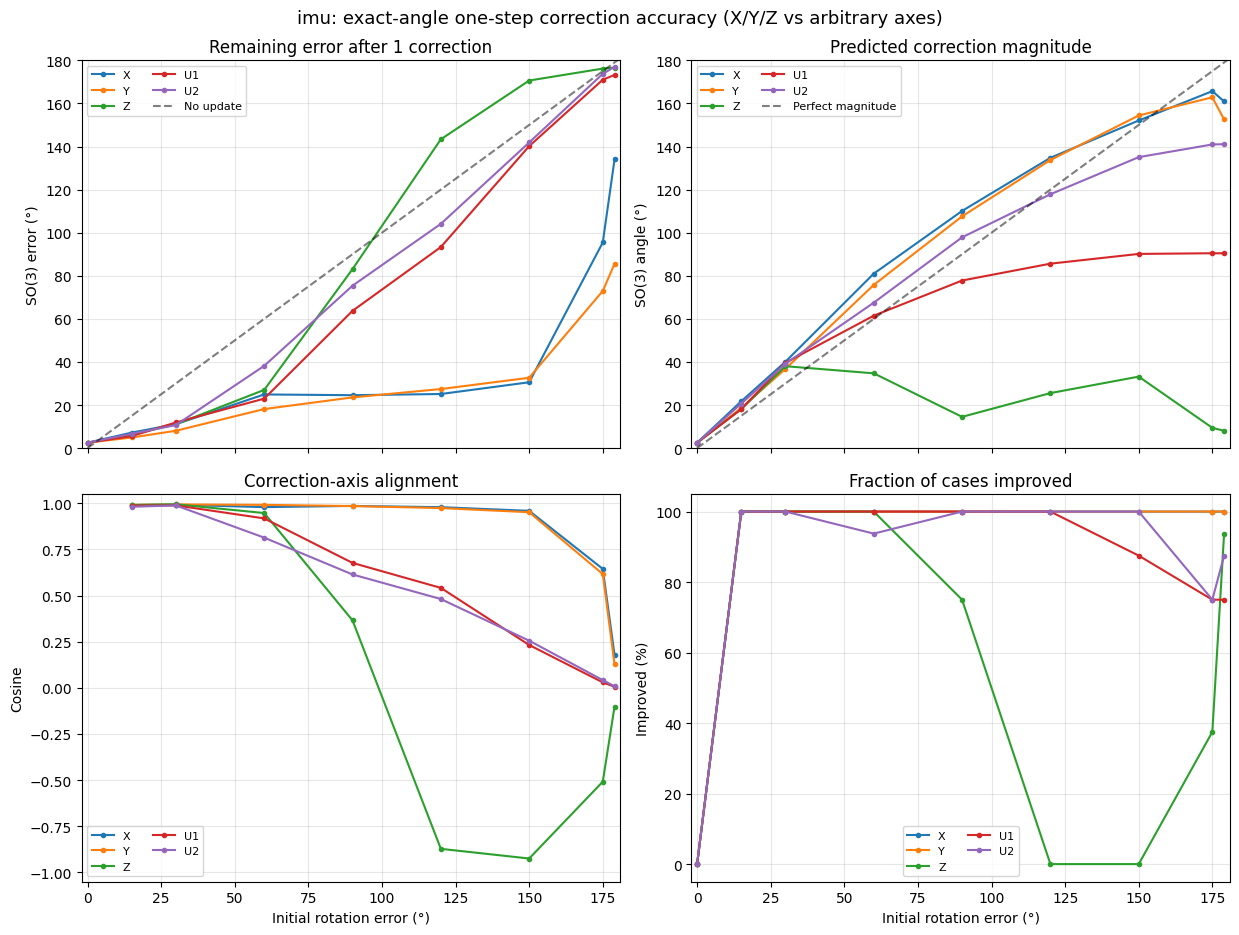

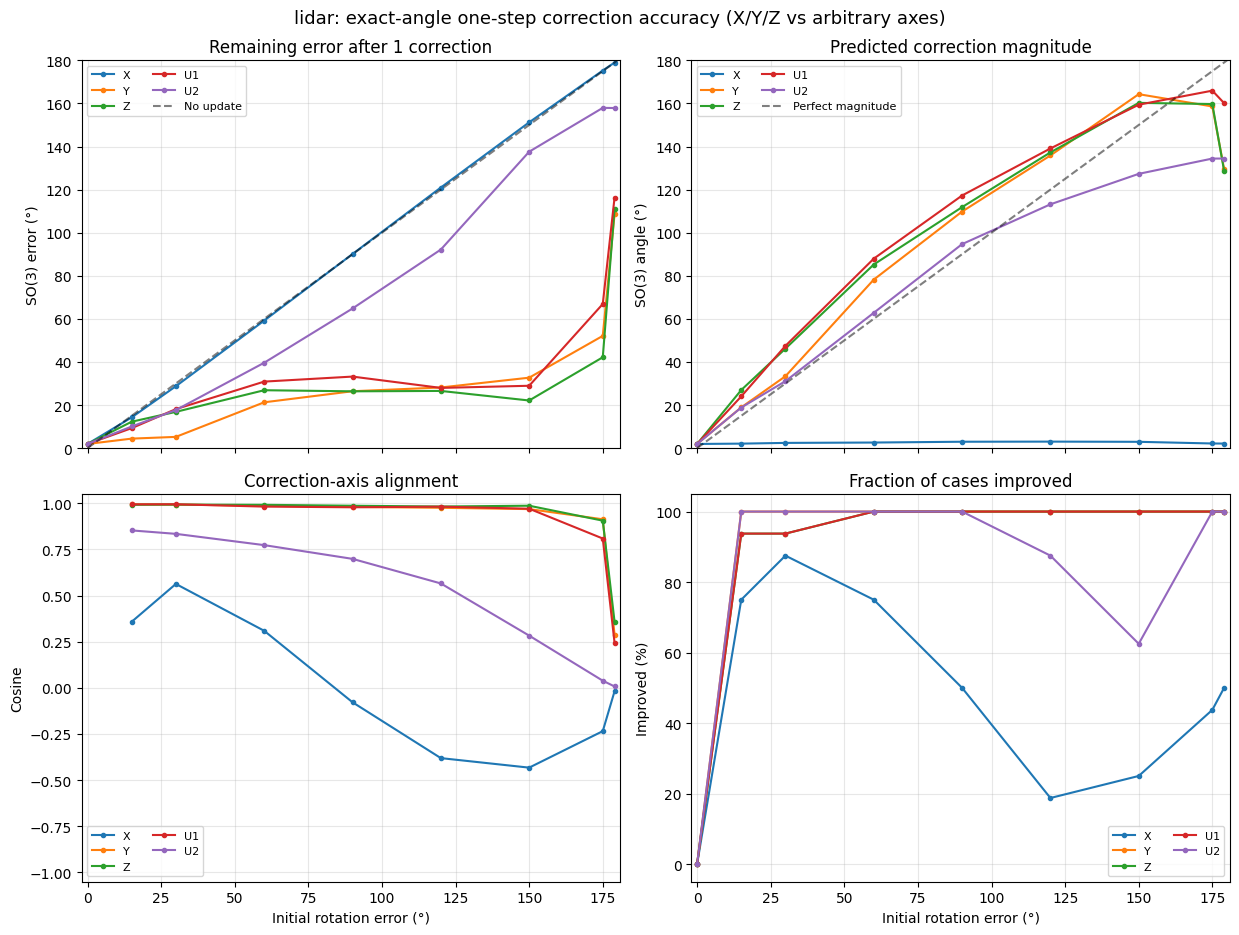

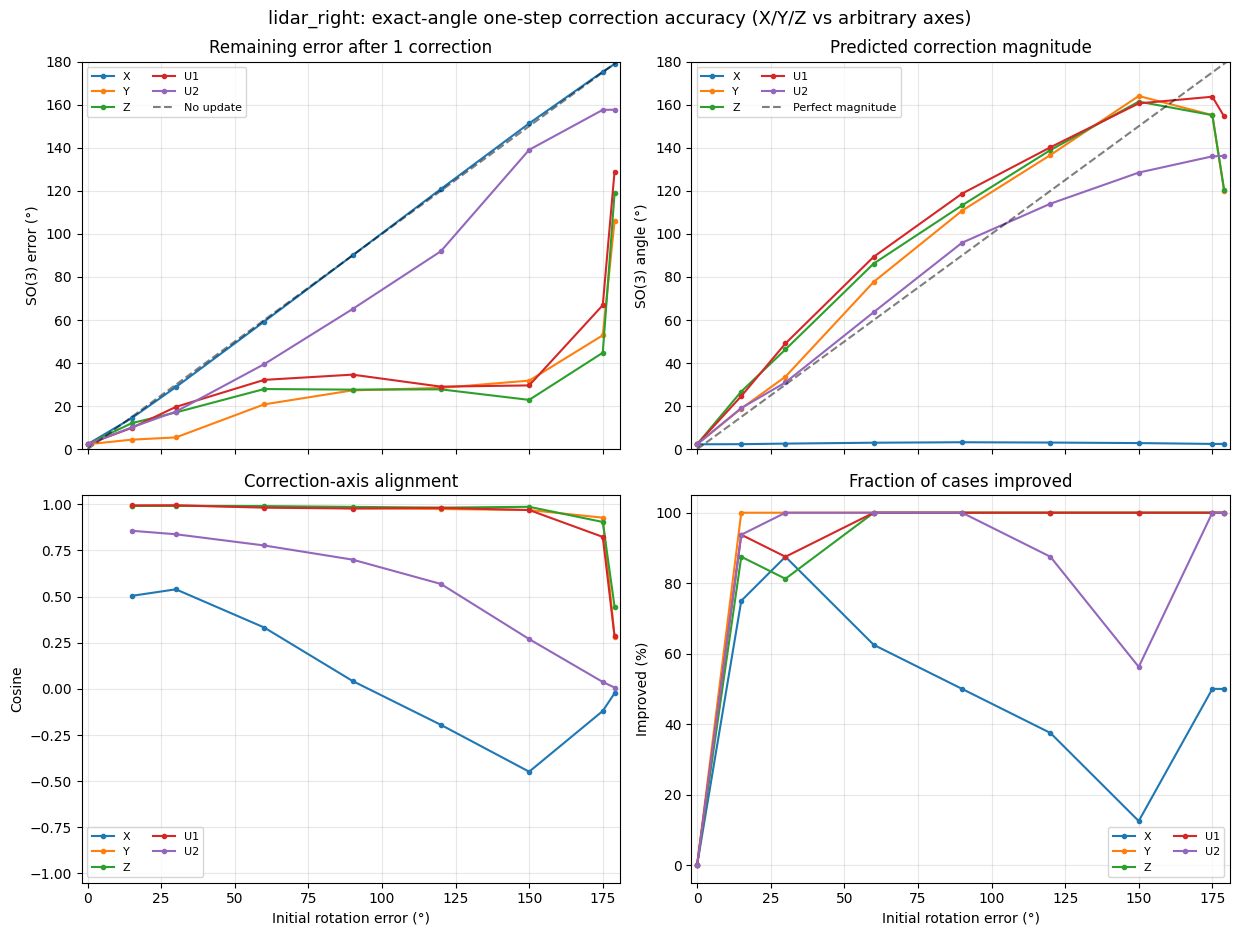

Saved one-step cases, summaries and figures under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_direction_magnitude/plots/so3_correction_diagnostics


In [76]:
# Exact-angle one-step corrections on held-out physical windows. No checkpoint or weights are modified.
@torch.inference_mode()
def diag65_run_one_step():
    indices = np.asarray(val_dataset.window_indices_for_sequence(VAL_NAMES[0]), dtype=int)
    chosen = indices[np.unique(np.linspace(0, len(indices) - 1, min(DIAG65_NUM_PHYSICAL_WINDOWS, len(indices))).round().astype(int))]
    base_window = window_batch_to(collate_windows([val_dataset[int(i)] for i in chosen]), DEVICE, dtype=MODEL_DTYPE)
    physical = context_augmentation_pipeline(base_window, generator=make_augmentation_generator(DIAG65_PHYSICAL_SEED)).augmented_window
    truth = physical.current_calibration
    batch_size = len(chosen)
    rows = []
    was_training = model.training
    model.eval()
    try:
        for key in DIAG65_FAULT_KEYS:
            for axis_name in DIAG65_AXIS_NAMES:
                axis = DIAG65_AXES[axis_name]
                for angle in DIAG65_ANGLES_DEG:
                    for sign in ((1,) if angle == 0.0 else (-1, 1)):
                        xi = {name: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for name in CALIBRATION_KEYS}
                        tau = {name: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for name in CALIBRATION_KEYS}
                        xi[key][:, :3] = sign * np.deg2rad(angle) * axis
                        prior = apply_prior_perturbation(truth, xi, tau)
                        probe_window = clone_window_with_calibration(physical, prior)
                        prediction = window_step(probe_window).model_output.predictions[key]
                        predicted_phi = prediction.delta_xi[:, :3]
                        true_xi, _ = correction_target(probe_window, key)
                        true_phi = true_xi[:, :3]
                        R_prior = prior[key].transform[:, :3, :3]
                        R_truth = truth[key].transform[:, :3, :3]
                        R_after = so3_exp(predicted_phi) @ R_prior   # Left-composed rotation update, as in calibration targets.
                        initial = diag65_rotation_distance_deg(R_prior, R_truth)
                        residual = diag65_rotation_distance_deg(R_after, R_truth)
                        R_predicted = so3_exp(predicted_phi)
                        R_identity = torch.eye(3, device=DEVICE, dtype=MODEL_DTYPE).expand_as(R_predicted)
                        predicted_angle = diag65_rotation_distance_deg(R_predicted, R_identity)
                        cos_axis = F.cosine_similarity(predicted_phi, true_phi, dim=-1)
                        cos_axis = torch.where((predicted_phi.norm(dim=-1) > np.deg2rad(1.0)) & (true_phi.norm(dim=-1) > np.deg2rad(1.0)), cos_axis, torch.nan)
                        if not torch.isfinite(residual).all() or (initial - angle).abs().max() > 0.25:
                            raise RuntimeError(f'Invalid exact-angle probe, key={key} axis={axis_name} angle={angle}°')
                        for j in range(batch_size):
                            before, after = float(initial[j]), float(residual[j])
                            rows.append(dict(key=key, axis=axis_name, signed_angle_deg=float(sign * angle), initial_deg=before,
                                             angle_deg=float(angle), window_index=int(chosen[j]), residual_deg=after,
                                             gain_deg=before - after, predicted_deg=float(predicted_angle[j]),
                                             axis_cos=float(cos_axis[j]), improved=bool(after < before - 1e-4),
                                             success_10deg=bool(after < 10.0)))
    finally:
        model.train(was_training)
    return pd.DataFrame(rows)


diag65_one_df = diag65_run_one_step()
diag65_one_df.to_csv(DIAG65_OUTPUT_DIR / 'one_step_cases.csv', index=False)
diag65_one_summary = diag65_one_df.groupby(['key', 'axis', 'angle_deg'], as_index=False).agg(
    mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'),
    mean_predicted_deg=('predicted_deg', 'mean'), mean_gain_deg=('gain_deg', 'mean'),
    axis_cos=('axis_cos', 'mean'), improved_fraction=('improved', 'mean'),
    success_10deg=('success_10deg', 'mean'), n=('residual_deg', 'size'))
diag65_one_summary.to_csv(DIAG65_OUTPUT_DIR / 'one_step_summary.csv', index=False)

print('One-step SO(3) errors on validation physical windows; positive gain means improvement.')
print(diag65_one_df.groupby(['key', 'angle_deg'], as_index=False).agg(
    residual_deg=('residual_deg', 'mean'), gain_deg=('gain_deg', 'mean'), predicted_deg=('predicted_deg', 'mean'),
    improved_pct=('improved', lambda x: 100 * x.mean()), n=('residual_deg', 'size')).round(2).to_string(index=False))

for key in DIAG65_FAULT_KEYS:
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.5), sharex=True)
    for axis_name in DIAG65_AXIS_NAMES:
        curve = diag65_one_summary[(diag65_one_summary.key == key) & (diag65_one_summary.axis == axis_name)].sort_values('angle_deg')
        x = curve.angle_deg
        axes[0, 0].plot(x, curve.mean_residual_deg, '-o', markersize=3, label=axis_name)
        axes[0, 1].plot(x, curve.mean_predicted_deg, '-o', markersize=3, label=axis_name)
        axes[1, 0].plot(x, curve.axis_cos, '-o', markersize=3, label=axis_name)
        axes[1, 1].plot(x, 100 * curve.improved_fraction, '-o', markersize=3, label=axis_name)
    axes[0, 0].plot([0, 180], [0, 180], 'k--', alpha=0.5, label='No update')
    axes[0, 1].plot([0, 180], [0, 180], 'k--', alpha=0.5, label='Perfect magnitude')
    axes[0, 0].set(title='Remaining error after 1 correction', ylabel='SO(3) error (°)', ylim=(0, 180))
    axes[0, 1].set(title='Predicted correction magnitude', ylabel='SO(3) angle (°)', ylim=(0, 180))
    axes[1, 0].set(title='Correction-axis alignment', xlabel='Initial rotation error (°)', ylabel='Cosine', ylim=(-1.05, 1.05))
    axes[1, 1].set(title='Fraction of cases improved', xlabel='Initial rotation error (°)', ylabel='Improved (%)', ylim=(-5, 105))
    for ax in axes.flat:
        ax.set_xlim(-2, 181)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
    fig.suptitle(f'{key}: exact-angle one-step correction accuracy (X/Y/Z vs arbitrary axes)', fontsize=13)
    fig.tight_layout()
    fig.savefig(DIAG65_OUTPUT_DIR / f'{key}_one_step.png', dpi=160)
    plt.show()

print('Saved one-step cases, summaries and figures under:', DIAG65_OUTPUT_DIR)


## 25C. Multi-window chronological rollouts
Each predicted update is fed into the next consecutive 5-second window. The true calibration re-expression is held constant across the sequence. Default: 12 windows, U1 axis, three sensors, ± faults, rotation-only updates to the faulted sensor. Set ROLL65_UPDATE_MODE = "full_se3" or ROLL65_UPDATE_ALL_KEYS = True in the setup cell for more demanding tests.

Completed rollouts: Urban26, start=0, axes=('U1',), update_mode=rotation_only
Mean residual (°) at each stage. Values below the initial angle indicate improvement.
step                                   0      1      3      6      12
key         axis initial_angle_deg                                   
imu         U1   0.0                  0.0    0.1    3.2    5.4   11.3
                 30.0                30.0    9.4    3.6    5.4   11.3
                 60.0                60.0   29.9    4.3    5.5   11.3
                 90.0                90.0   64.2   14.9    5.8   11.3
                 120.0              120.0   98.5   91.8   90.8   84.5
                 150.0              150.0  141.4  174.5  177.4  157.6
                 175.0              175.0  162.7  178.9  177.5  157.6
                 179.0              179.0  162.5  178.9  177.5  157.6
lidar       U1   0.0                  0.0    2.5   12.3   10.5   45.7
                 30.0                30.0   15.1    7.2    7.8   4

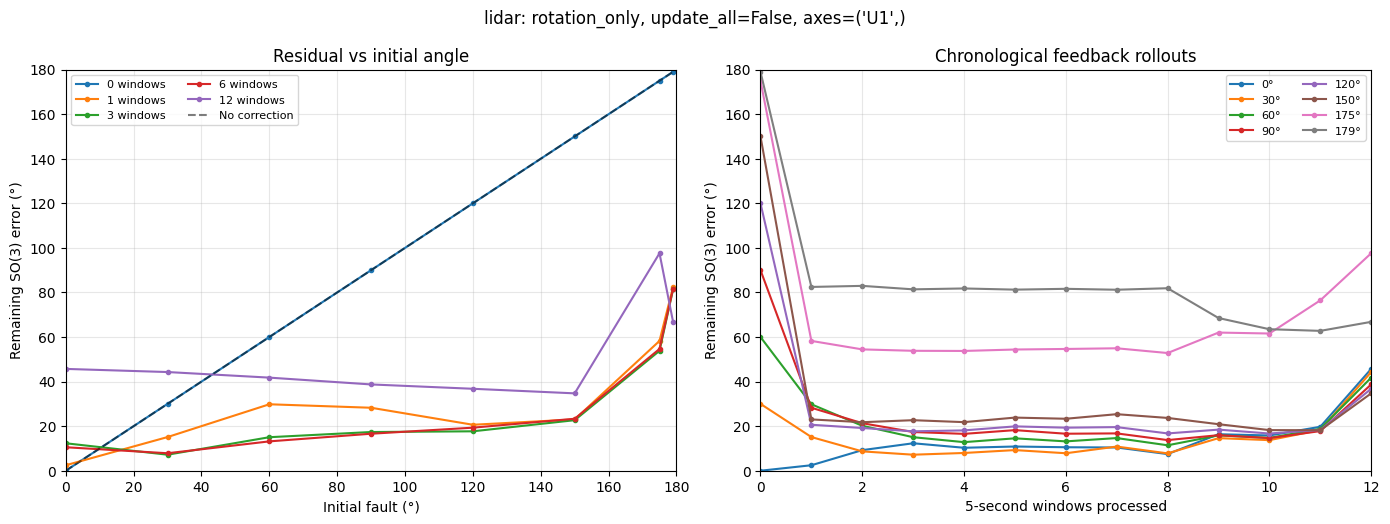

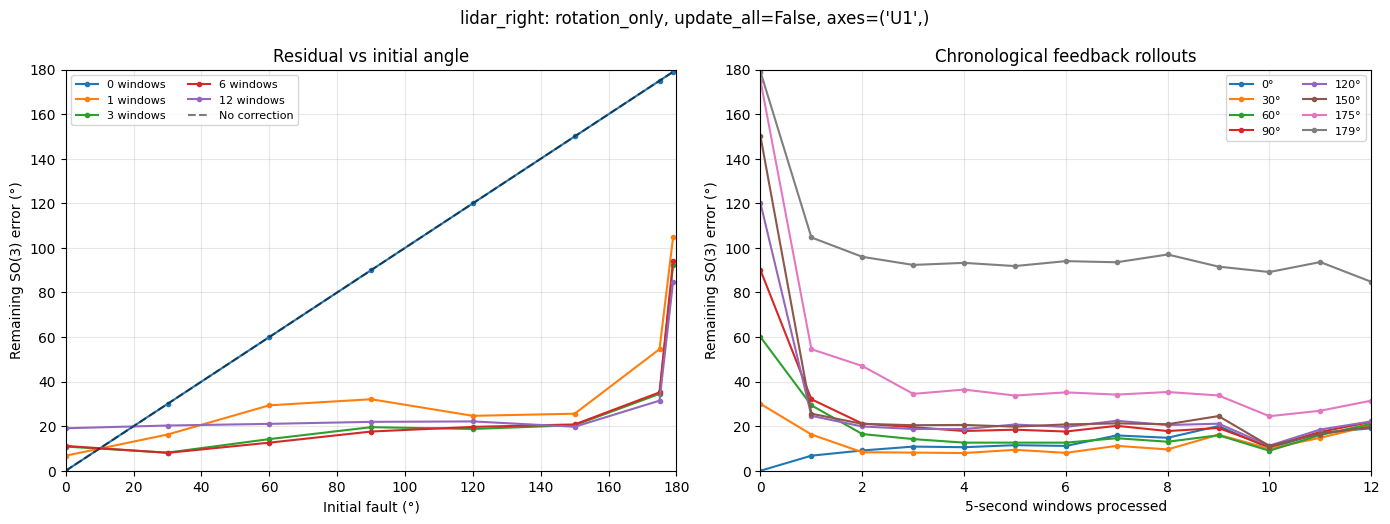

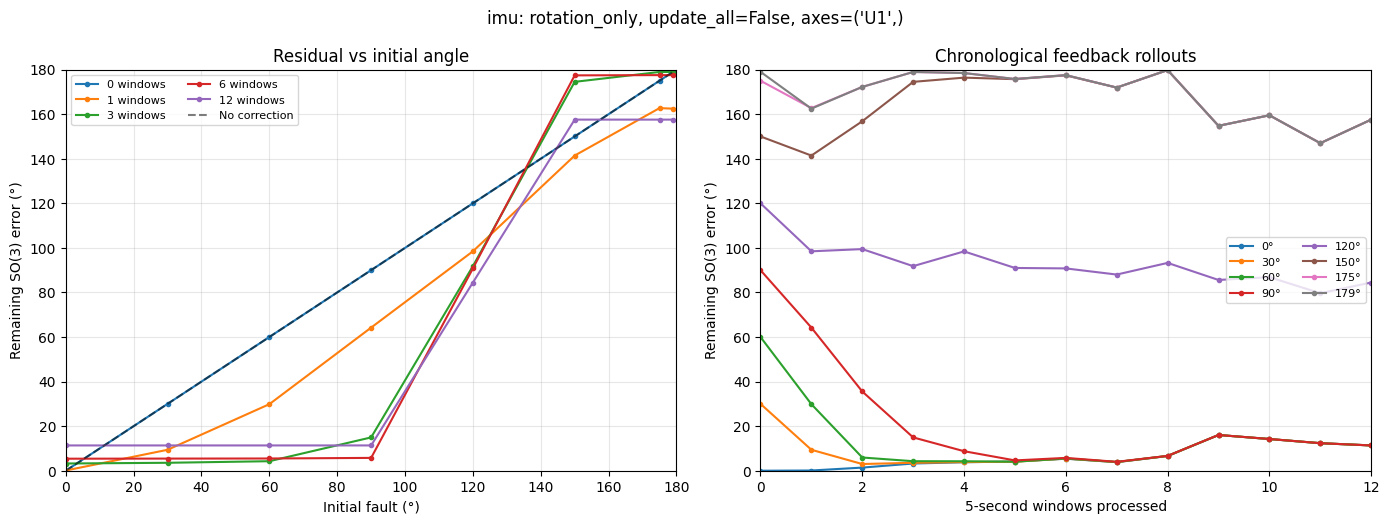

Saved rollout cases, summaries and figures under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_direction_magnitude/plots/so3_correction_diagnostics
Evaluation only: model parameters, optimizer and scheduler were not updated.


In [77]:
# Chronological-feedback rollouts with exact initial rotation faults.
# Unlike applying a network repeatedly to one window, every step uses the NEXT physical KAIST window.

def diag65_update_from_predictions(states, predictions, fault_key):
    update_keys = set(CALIBRATION_KEYS if ROLL65_UPDATE_ALL_KEYS else (fault_key,))
    updated = {}
    for key, state in states.items():
        if key not in update_keys:
            updated[key] = state
            continue
        pred = predictions[key]
        if ROLL65_UPDATE_MODE == 'rotation_only':
            transform = state.transform.clone()
            transform[:, :3, :3] = so3_exp(pred.delta_xi[:, :3]) @ state.transform[:, :3, :3]
            updated[key] = CalibrationState(transform=transform, time_offset=state.time_offset.clone())
        else:
            updated[key] = CalibrationState(transform=se3_exp(pred.delta_xi) @ state.transform, time_offset=state.time_offset + pred.delta_tau)
    return updated


@torch.inference_mode()
def diag65_run_rollouts():
    rows = []
    was_training = model.training
    model.eval()
    try:
        for sequence_number, sequence_name in enumerate(ROLL65_SEQUENCES):
            all_indices = np.asarray(val_dataset.window_indices_for_sequence(sequence_name), dtype=int)
            max_start = len(all_indices) - ROLL65_NUM_WINDOWS
            if max_start < 0:
                raise ValueError(f'{sequence_name} has {len(all_indices)} windows; need {ROLL65_NUM_WINDOWS}')
            starts = np.unique(np.linspace(0, max_start, min(ROLL65_STARTS_PER_SEQUENCE, max_start + 1)).round().astype(int))
            for start_number, start_pos in enumerate(starts):
                indices = all_indices[start_pos : start_pos + ROLL65_NUM_WINDOWS]
                physical_seed = ROLL65_PHYSICAL_SEED + sequence_number * 100_003 + start_number * 1_009
                physical_windows = []
                for index in indices:
                    raw = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=MODEL_DTYPE)
                    # Re-create the augmentation generator with the same seed for each window,
                    # so all chronological measurements share one fixed calibration truth.
                    physical = context_augmentation_pipeline(raw, generator=make_augmentation_generator(physical_seed)).augmented_window
                    physical_windows.append(physical)
                truth = diag65_copy_states(physical_windows[0].current_calibration)
                for physical in physical_windows[1:]:
                    for key in CALIBRATION_KEYS:
                        torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                        torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

                for fault_key in ROLL65_FAULT_KEYS:
                    for axis_name in ROLL65_AXIS_NAMES:
                        axis = DIAG65_AXES[axis_name]
                        for angle in ROLL65_ANGLES_DEG:
                            for sign in ((1,) if angle == 0.0 else (-1, 1)):
                                xi = {key: torch.zeros(1, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
                                tau = {key: torch.zeros(1, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
                                xi[fault_key][:, :3] = sign * np.deg2rad(angle) * axis
                                initial = apply_prior_perturbation(truth, xi, tau)
                                states = diag65_copy_states(initial)
                                for step in range(ROLL65_NUM_WINDOWS + 1):
                                    R_active = states[fault_key].transform[:, :3, :3]
                                    R_truth = truth[fault_key].transform[:, :3, :3]
                                    active_error = float(diag65_rotation_distance_deg(R_active, R_truth)[0])
                                    healthy_errors = [float(diag65_rotation_distance_deg(states[k].transform[:, :3, :3], truth[k].transform[:, :3, :3])[0]) for k in CALIBRATION_KEYS if k != fault_key]
                                    rows.append(dict(sequence=sequence_name, start_index=int(indices[0]), key=fault_key, axis=axis_name,
                                                     sign=int(sign), initial_angle_deg=float(angle), step=int(step),
                                                     elapsed_s=float(step * WINDOW_STRIDE_S), residual_deg=active_error,
                                                     gain_from_start_deg=float(angle - active_error), healthy_mean_deg=float(np.mean(healthy_errors))))
                                    if step == ROLL65_NUM_WINDOWS:
                                        break
                                    inp = clone_window_with_calibration(physical_windows[step], states)
                                    predictions = window_step(inp).model_output.predictions
                                    states = diag65_update_from_predictions(states, predictions, fault_key)
                print(f'Completed rollouts: {sequence_name}, start={int(indices[0])}, axes={ROLL65_AXIS_NAMES}, update_mode={ROLL65_UPDATE_MODE}', flush=True)
    finally:
        model.train(was_training)
    return pd.DataFrame(rows)


roll65_df = diag65_run_rollouts()
roll65_df.to_csv(DIAG65_OUTPUT_DIR / 'rollout_cases.csv', index=False)
roll65_summary = roll65_df.groupby(['key', 'axis', 'initial_angle_deg', 'step'], as_index=False).agg(
    mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'),
    p90_residual_deg=('residual_deg', lambda x: np.percentile(x, 90)),
    success_10deg=('residual_deg', lambda x: (x < 10).mean()),
    fraction_improved=('gain_from_start_deg', lambda x: (x > 1e-4).mean()),
    healthy_mean_deg=('healthy_mean_deg', 'mean'), n=('residual_deg', 'size'))
roll65_summary.to_csv(DIAG65_OUTPUT_DIR / 'rollout_summary.csv', index=False)

print('Mean residual (°) at each stage. Values below the initial angle indicate improvement.')
stages = sorted(set((0, 1, 3, 6, ROLL65_NUM_WINDOWS)) & set(roll65_summary.step.unique()))
print(roll65_summary[roll65_summary.step.isin(stages)].pivot_table(
    index=['key', 'axis', 'initial_angle_deg'], columns='step', values='mean_residual_deg').round(1).to_string())
print('\nFinal convergence probabilities by sensor and initial angle:')
print(roll65_df[roll65_df.step == ROLL65_NUM_WINDOWS].groupby(['key', 'initial_angle_deg']).agg(
    final_mean_deg=('residual_deg', 'mean'), final_median_deg=('residual_deg', 'median'),
    improved_pct=('gain_from_start_deg', lambda x: 100 * (x > 1e-4).mean()),
    success_10deg_pct=('residual_deg', lambda x: 100 * (x < 10).mean()),
    n=('residual_deg', 'size')).round(2).to_string())

for key in ROLL65_FAULT_KEYS:
    subset = roll65_df[roll65_df.key == key]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.3))
    for step in stages:
        curve = subset[subset.step == step].groupby('initial_angle_deg', as_index=False).residual_deg.mean().sort_values('initial_angle_deg')
        axes[0].plot(curve.initial_angle_deg, curve.residual_deg, '-o', markersize=3, label=f'{step} windows')
    axes[0].plot([0, 180], [0, 180], 'k--', alpha=0.5, label='No correction')
    axes[0].set(title='Residual vs initial angle', xlabel='Initial fault (°)', ylabel='Remaining SO(3) error (°)', xlim=(0, 180), ylim=(0, 180))
    for angle in ROLL65_ANGLES_DEG:
        curve = subset[subset.initial_angle_deg == angle].groupby('step', as_index=False).residual_deg.mean().sort_values('step')
        axes[1].plot(curve.step, curve.residual_deg, '-o', markersize=3, label=f'{angle:g}°')
    axes[1].set(title='Chronological feedback rollouts', xlabel='5-second windows processed', ylabel='Remaining SO(3) error (°)', xlim=(0, ROLL65_NUM_WINDOWS), ylim=(0, 180))
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
    fig.suptitle(f'{key}: {ROLL65_UPDATE_MODE}, update_all={ROLL65_UPDATE_ALL_KEYS}, axes={ROLL65_AXIS_NAMES}')
    fig.tight_layout()
    fig.savefig(DIAG65_OUTPUT_DIR / f'{key}_rollouts.png', dpi=160)
    plt.show()

print('Saved rollout cases, summaries and figures under:', DIAG65_OUTPUT_DIR)
print('Evaluation only: model parameters, optimizer and scheduler were not updated.')


In [78]:
torch.cuda.empty_cache()